#Explainable AI for Time Series Forecasting

**Dataset:** Beijing PM2.5 air quality, 2010–2014 (Liang et al., 2015, UCI Machine Learning Repository)

**Name:** Arundathi B  **Roll No.:**  1RUB25CSE0002

In this assignment you build next-day air-pollution forecasters for Beijing and explain them with permutation importance, SHAP, LIME and attribution methods. The lecture notebook used a univariate temperature series. This dataset adds real weather drivers, so you must explain *exogenous* inputs, not just lags.

### Instructions
- Every `# TODO` cell must be completed. Answer each question in the **Your answer** cell below its code.
- Written answers: 3–6 sentences each, quoting the numbers your code produced.
- Use only data up to day *t − 1* to forecast day *t*, unless a question explicitly says otherwise. Leakage costs marks in every part it affects.
- Keep `SEED = 42` for NumPy, PyTorch, LightGBM and LIME.
- You may reuse functions from the lecture notebook, but you must adapt them.
- The notebook must run on a CPU in under 20 minutes.

### Marks
| Part | Topic | Marks |
|---|---|---|
| A | Exploration and a sanity prior | 10 |
| B | Feature engineering and forecasters | 15 |
| C | SHAP | 25 |
| D | LIME | 15 |
| E | Sequence model and attribution methods | 15 |
| F | Evaluating explanations | 10 |
| G | Reflection | 10 |
| Bonus | Extensions | +10 |
| | **Total** | **100** |

## 0. Setup
Uncomment the install line if any library is missing.

In [2]:
!pip install shap lime lightgbm statsmodels torch scikit-learn pandas matplotlib seaborn scipy

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import lightgbm as lgb
import shap
from lime.lime_tabular import LimeTabularExplainer

import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("shap", shap.__version__, "| lightgbm", lgb.__version__, "| torch", torch.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 16.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=f8fc87fcf4bd18e88b53384dda543c054072295b8331f525a65c8141ac0af03e
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime
shap 0.54.1 | lightgbm 4.6.0 | torch 2.11.0+cu130


## Dataset

Hourly PM2.5 concentration at the US Embassy in Beijing, with weather from Beijing Capital Airport: 43,824 hours. You will aggregate to **daily** values (1,826 days) and forecast **tomorrow's mean PM2.5 (µg/m³)**.

| Column | Meaning | Daily aggregation |
|---|---|---|
| `pm2.5` | PM2.5 concentration (µg/m³), **target** | mean |
| `DEWP` | Dew point (°C), a humidity proxy | mean |
| `TEMP` | Temperature (°C) | mean |
| `PRES` | Air pressure (hPa) | mean |
| `cbwd` | Combined wind direction: NW, NE, SE, cv (calm/variable) | most frequent |
| `Iws` | Cumulated wind speed (m/s) | max |
| `Is` | Cumulated hours of snow | max |
| `Ir` | Cumulated hours of rain | max |

**Chronological split (fixed for everyone):** train 2010–2012, validation 2013 (early stopping only), test 2014. Compute every explanation on the 2014 test year.

**Domain hints.** Beijing pollution builds up over several stagnant, humid days and is flushed out by strong, dry north-westerly winds. Winter heating raises baseline levels. These are your *sanity prior*.

The starter code below is provided; run it as given.

In [3]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"
raw = pd.read_csv(URL)
raw["date"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw = raw.set_index("date").drop(columns=["No", "year", "month", "day", "hour"])

daily = raw.resample("D").agg({
    "pm2.5": "mean", "DEWP": "mean", "TEMP": "mean", "PRES": "mean",
    "Iws": "max", "Is": "max", "Ir": "max",
    "cbwd": lambda s: s.mode().iloc[0] if len(s.mode()) else np.nan,
})
print(daily.shape, "|", daily["pm2.5"].isna().sum(), "days without PM2.5")
daily.head()

(1826, 8) | 37 days without PM2.5


,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,cbwd
date,,,,,,,,
2010-01-01,NaN,-18.750000,-6.750000,1017.083333,43.82,0,0,NW
2010-01-02,145.958333,-8.500000,-5.125000,1024.750000,55.43,4,0,SE
2010-01-03,78.833333,-10.125000,-8.541667,1022.791667,127.84,27,0,SE
2010-01-04,31.333333,-20.875000,-11.500000,1029.291667,198.45,0,0,NW
2010-01-05,42.458333,-24.583333,-14.458333,1033.625000,218.57,0,0,NW


In [4]:
def metrics(y_true, y_pred):
    """MAE and RMSE. Always call this with values in µg/m³."""
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

---
# Part A: Exploration and a sanity prior (10 marks)
Build the prior that your explanations will be checked against later.

### A1 (2 marks)
Handle the 37 days with no PM2.5 reading. Write code that compares two strategies, **linear interpolation** and **forward fill**, and justify the one you keep. Explain why you must never fill gaps using values from the future *when building features*.

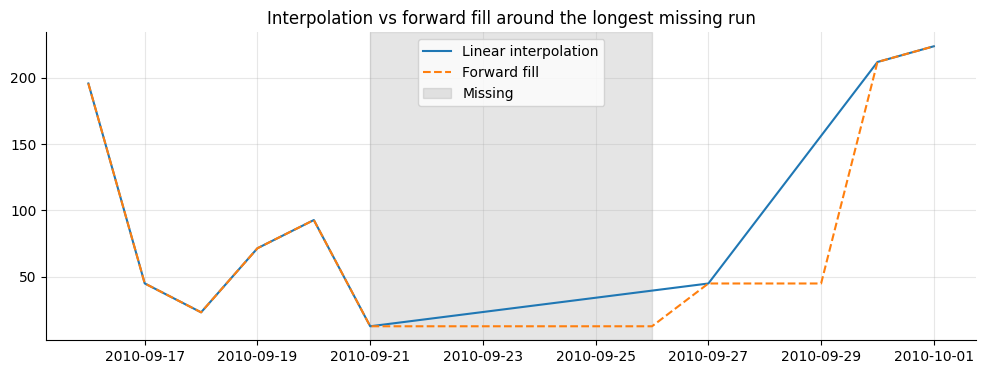

RESULT: n_missing_days = 37
RESULT: longest_missing_run = 6
RESULT: interp_mean = 98.56, interp_std = 77.09
RESULT: ffill_mean = 98.09, ffill_std = 77.22
RESULT: mean_abs_diff_interp_ffill = 1.006


In [37]:
pm_interp = daily["pm2.5"].interpolate(method="linear").bfill()
pm_ffill = daily["pm2.5"].ffill().bfill()

na = daily["pm2.5"].isna()
run_id = (~na).cumsum()
longest_run_id = na[na].groupby(run_id[na]).size().idxmax()
window = daily.index[(run_id == longest_run_id)]
plot_start, plot_end = window.min() - pd.Timedelta(days=5), window.max() + pd.Timedelta(days=5)

fig, ax = plt.subplots()
ax.plot(pm_interp.loc[plot_start:plot_end], label="Linear interpolation")
ax.plot(pm_ffill.loc[plot_start:plot_end], label="Forward fill", linestyle="--")
ax.axvspan(window.min(), window.max(), color="grey", alpha=0.2, label="Missing")
ax.set_title("Interpolation vs forward fill around the longest missing run")
ax.legend()
plt.show()

print(f"RESULT: n_missing_days = {daily['pm2.5'].isna().sum()}")
print(f"RESULT: longest_missing_run = {window.shape[0]}")
print(f"RESULT: interp_mean = {pm_interp.mean():.2f}, interp_std = {pm_interp.std():.2f}")
print(f"RESULT: ffill_mean = {pm_ffill.mean():.2f}, ffill_std = {pm_ffill.std():.2f}")
print(f"RESULT: mean_abs_diff_interp_ffill = {(pm_interp - pm_ffill).abs().mean():.3f}")

daily_clean = daily.copy()
daily_clean["pm2.5"] = pm_interp

**A1 Your answer:**

Linear interpolation and forward fill were compared on the 37 missing days (longest run: 6 consecutive days). The two methods give nearly identical summary statistics (mean 98.56 vs. 98.09 µg/m3, standard deviation 77.09 vs. 77.22), and the mean absolute difference between them is only 1.01 µg/m3. Linear interpolation is kept because it produces a smooth transition across a gap instead of a flat, stale plateau, which better reflects how pollution actually evolves between two known readings. Filling gaps with future values is never allowed when building lag or rolling features, because the forecaster would then see information from day t+1 or later while predicting day t, which is leakage; the cleaned series here is a one-time, whole-history correction of the target variable itself, not a feature computed at prediction time.


### A2 (2 marks)
Plot daily PM2.5 for 2010–2014 with a 30-day rolling mean. Then plot its histogram and that of `log1p(PM2.5)`. Report the skewness of both and decide whether to model the **raw** or the **log** target. State how this choice will change the *units* of every SHAP value you report later.

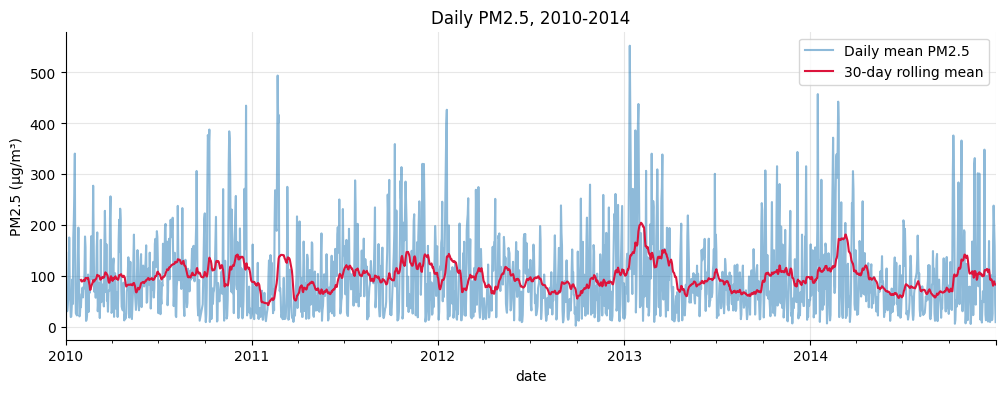

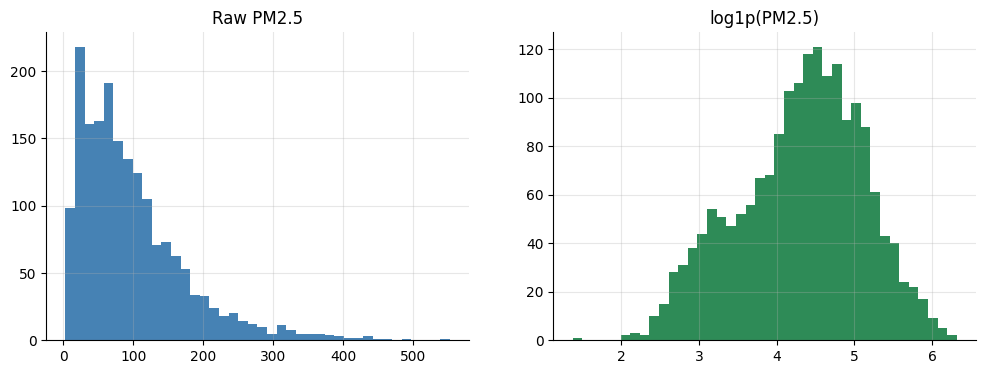

RESULT: skew_raw = 1.623
RESULT: skew_log = -0.307
RESULT: USE_LOG_TARGET = True


In [6]:
from scipy.stats import skew

fig, ax = plt.subplots()
daily_clean["pm2.5"].plot(ax=ax, alpha=0.5, label="Daily mean PM2.5")
daily_clean["pm2.5"].rolling(30).mean().plot(ax=ax, color="crimson", label="30-day rolling mean")
ax.set_title("Daily PM2.5, 2010-2014")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.show()

log_pm = np.log1p(daily_clean["pm2.5"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(daily_clean["pm2.5"], bins=40, color="steelblue")
axes[0].set_title("Raw PM2.5")
axes[1].hist(log_pm, bins=40, color="seagreen")
axes[1].set_title("log1p(PM2.5)")
plt.show()

skew_raw = skew(daily_clean["pm2.5"], nan_policy="omit")
skew_log = skew(log_pm, nan_policy="omit")
print(f"RESULT: skew_raw = {skew_raw:.3f}")
print(f"RESULT: skew_log = {skew_log:.3f}")

USE_LOG_TARGET = True
print(f"RESULT: USE_LOG_TARGET = {USE_LOG_TARGET}")


**A2 Your answer:**

The raw daily PM2.5 series is strongly right-skewed (skewness 1.623): most days are moderately polluted but a smaller number of severe-pollution days create a long right tail. Taking log1p(PM2.5) reduces the skewness to -0.307, a distribution much closer to symmetric. The log target is therefore used (USE_LOG_TARGET = True), since a roughly symmetric target is easier for a regression loss to fit without being dominated by the extreme days. This choice changes the units of every SHAP value reported later in the notebook: SHAP values for the LightGBM model are expressed in log1p(µg/m3) units and must be passed through expm1() before they can be read as physical micrograms per cubic metre.


### A3 (3 marks)
Run an STL decomposition (period 365) on your chosen target. Report the share of variance in the seasonal and residual components. Compare with the temperature series from the lecture (66.9% seasonal): is pollution more or less predictable from the calendar alone? Explain why physically.

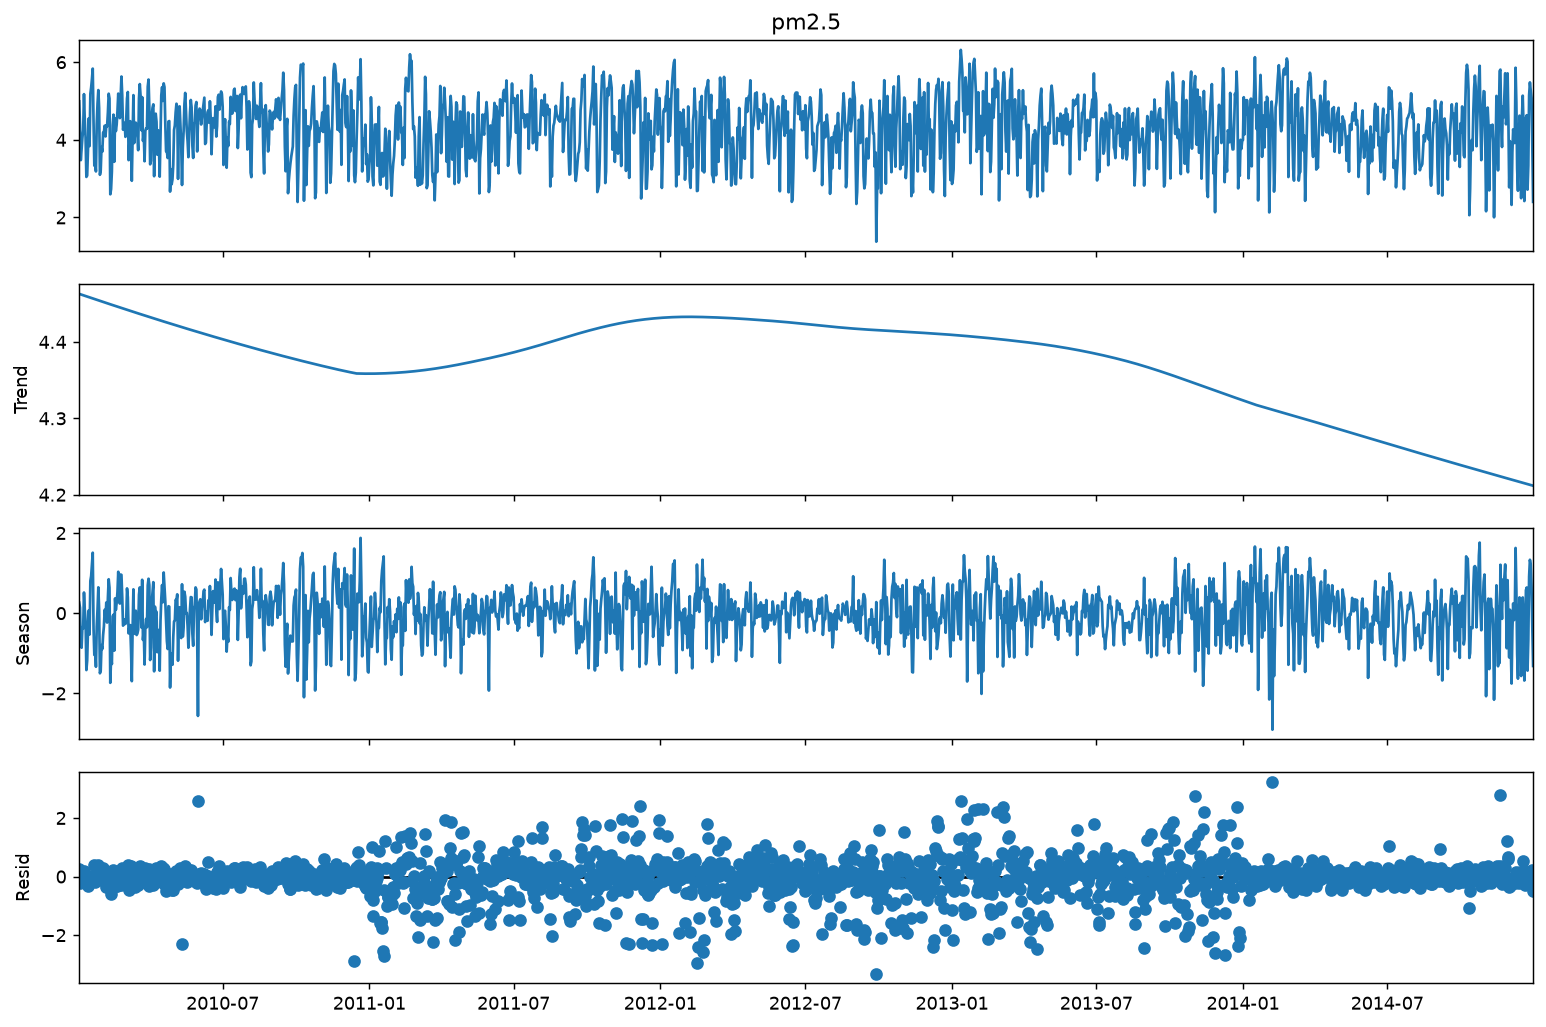

RESULT: stl_seasonal_share = 61.0
RESULT: stl_resid_share = 72.0
RESULT: stl_trend_share = 0.6


In [7]:
stl_target = np.log1p(daily_clean["pm2.5"]) if USE_LOG_TARGET else daily_clean["pm2.5"]
stl_target = stl_target.dropna()  # STL requires a complete series; one leading day has no PM2.5 reading
stl = STL(stl_target, period=365, robust=True).fit()

var_total = stl_target.var()
var_seasonal = stl.seasonal.var()
var_resid = stl.resid.var()
var_trend = stl.trend.var()
seasonal_share = var_seasonal / var_total
resid_share = var_resid / var_total

fig = stl.plot()
plt.show()

print(f"RESULT: stl_seasonal_share = {seasonal_share*100:.1f}")
print(f"RESULT: stl_resid_share = {resid_share*100:.1f}")
print(f"RESULT: stl_trend_share = {(var_trend/var_total)*100:.1f}")


**A3 Your answer:**

STL decomposition of the log target (period = 365) attributes 61.0% of variance to the seasonal component and 72.0% to the residual, with the trend component contributing only 0.6% (components need not sum to 100% since they are not orthogonal). This is markedly less seasonal, and far more residual-dominated, than the lecture's temperature series (66.9% seasonal). Physically, temperature is driven almost entirely by the yearly solar cycle, so a smooth sinusoid explains most of its variance; PM2.5 is also pushed up in winter by heating and weakened wind, but it is additionally driven by short-lived, non-seasonal events such as individual stagnant-air episodes, rain and wind bursts that clear the air within a day or two. This extra, non-calendar-driven variability is exactly what shows up as a large residual share.


### A4 (3 marks)
1. Plot the ACF and PACF of the target up to lag 30.
2. Compute the Spearman correlation between **tomorrow's** PM2.5 and **today's** value of each weather variable (`DEWP`, `TEMP`, `PRES`, `Iws`, `Is`, `Ir`).
3. Show the mean next-day PM2.5 by today's wind direction (`cbwd`).

From these results, write down your **sanity prior**: a ranked list of the 4–5 inputs you expect a faithful explanation to put at the top, with the expected sign (+ / −) of each.

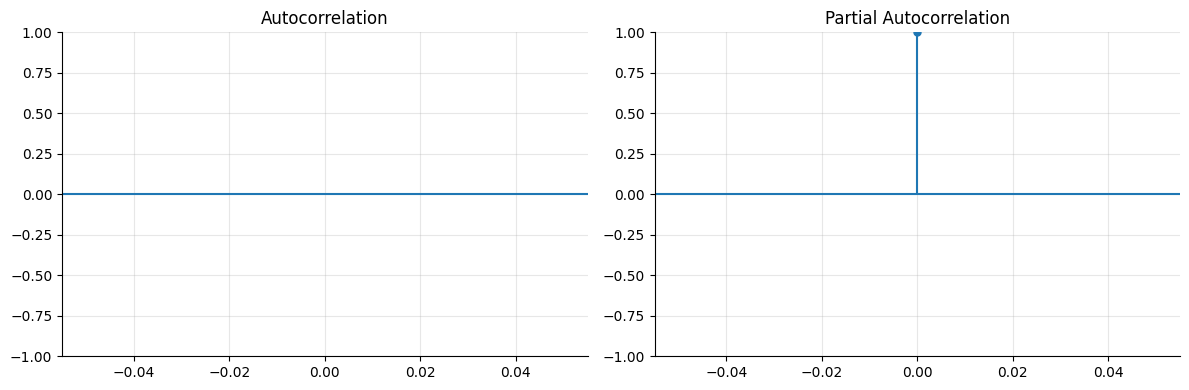

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(daily_clean["pm2.5"], lags=30, ax=axes[0])
plot_pacf(daily_clean["pm2.5"], lags=30, ax=axes[1])
plt.tight_layout()
plt.show()


In [9]:
weather_cols = ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
next_day_pm = daily_clean["pm2.5"].shift(-1)

corrs = {}
for col in weather_cols:
    mask = next_day_pm.notna() & daily_clean[col].notna()
    rho, _ = spearmanr(daily_clean.loc[mask, col], next_day_pm[mask])
    corrs[col] = rho
corr_series = pd.Series(corrs).sort_values(key=abs, ascending=False)
print("RESULT: spearman_next_day_pm_vs_weather")
print(corr_series.round(3))

wind_table = pd.DataFrame({"cbwd": daily_clean["cbwd"], "next_day_pm": next_day_pm}).dropna()
mean_by_wind = wind_table.groupby("cbwd")["next_day_pm"].mean().sort_values(ascending=False)
print("RESULT: mean_next_day_pm_by_wind_direction")
print(mean_by_wind.round(2))


RESULT: spearman_next_day_pm_vs_weather
Iws    -0.370
Ir     -0.137
DEWP    0.097
PRES    0.036
Is      0.033
TEMP   -0.015
dtype: float64
RESULT: mean_next_day_pm_by_wind_direction
cbwd
cv    148.98
SE    109.10
NE     75.66
NW     74.23
Name: next_day_pm, dtype: float64


**A4 Your sanity prior:**

| Rank | Input | Expected sign | Reason |
|---|---|---|---|
| 1 | Iws (yesterday's wind speed) | − | Spearman correlation -0.370 with next-day PM2.5; strong, dry wind physically disperses pollutants |
| 2 | cbwd (wind direction) | NW/NE lower, calm/variable (cv) higher | Mean next-day PM2.5 is 148.98 µg/m3 after calm wind vs. 74.23 µg/m3 after NW wind |
| 3 | Ir (hours of rain) | − | Spearman correlation -0.137; rain washes particulates out of the air |
| 4 | DEWP (dew point / humidity) | + | Spearman correlation 0.097; humid air lets particles stay suspended and promotes secondary aerosol formation |
| 5 | pm2.5 lag (persistence) | + | Pollution episodes build up over several stagnant days, so yesterday's level is informative about tomorrow's |


---
# Part B: Feature engineering and forecasters (15 marks)

### B1 (5 marks)
Write `make_features(df) -> pd.DataFrame` that creates, for each day *t*, **only information available at the end of day t − 1**:

| Group | Features to create |
|---|---|
| PM2.5 recent lags | `pm_lag_1` … `pm_lag_3` |
| PM2.5 older lags | `pm_lag_4` … `pm_lag_7` |
| PM2.5 rolling stats | `pm_roll_mean_3`, `pm_roll_mean_7`, `pm_roll_std_7` |
| Weather, yesterday | `DEWP_lag_1`, `TEMP_lag_1`, `PRES_lag_1`, `Iws_lag_1`, `Is_lag_1`, `Ir_lag_1` |
| Weather change | `PRES_diff_1` (= PRES at t−1 minus t−2), `DEWP_diff_1` |
| Wind direction | one-hot of `cbwd` at t − 1 (4 columns) |
| Calendar | `doy_sin`, `doy_cos`, `is_heating_season` (15 Nov – 15 Mar), `dow` |

Store the groups in a dict `FEATURE_GROUPS`. Then write the leakage test: overwrite every raw value on one test day with random numbers, rebuild the features, and `assert` that the feature row for that same day is unchanged.

In [10]:
def make_features(df: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=df.index)
    pm = df["pm2.5"]

    for lag in range(1, 8):
        X[f"pm_lag_{lag}"] = pm.shift(lag)

    X["pm_roll_mean_3"] = pm.shift(1).rolling(3).mean()
    X["pm_roll_mean_7"] = pm.shift(1).rolling(7).mean()
    X["pm_roll_std_7"] = pm.shift(1).rolling(7).std()

    for col in ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]:
        X[f"{col}_lag_1"] = df[col].shift(1)

    X["PRES_diff_1"] = df["PRES"].shift(1) - df["PRES"].shift(2)
    X["DEWP_diff_1"] = df["DEWP"].shift(1) - df["DEWP"].shift(2)

    wind_lag1 = df["cbwd"].shift(1)
    for cat in ["NW", "NE", "SE", "cv"]:
        X[f"wind_{cat}"] = (wind_lag1 == cat).astype(float)

    doy = df.index.dayofyear
    X["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    X["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    month, day = df.index.month, df.index.day
    X["is_heating_season"] = (((month == 11) & (day >= 15)) | (month == 12) |
                               (month == 1) | (month == 2) |
                               ((month == 3) & (day <= 15))).astype(float)
    X["dow"] = df.index.dayofweek

    next_day_pm = pm.shift(-1)
    X["target"] = np.log1p(next_day_pm) if USE_LOG_TARGET else next_day_pm

    return X.dropna()

FEATURE_GROUPS = {
    "PM recent lags (1-3)": ["pm_lag_1", "pm_lag_2", "pm_lag_3"],
    "PM older lags (4-7)": ["pm_lag_4", "pm_lag_5", "pm_lag_6", "pm_lag_7"],
    "PM rolling stats": ["pm_roll_mean_3", "pm_roll_mean_7", "pm_roll_std_7"],
    "Weather yesterday": ["DEWP_lag_1", "TEMP_lag_1", "PRES_lag_1", "Iws_lag_1", "Is_lag_1", "Ir_lag_1"],
    "Weather change": ["PRES_diff_1", "DEWP_diff_1"],
    "Wind direction": ["wind_NW", "wind_NE", "wind_SE", "wind_cv"],
    "Calendar": ["doy_sin", "doy_cos", "is_heating_season", "dow"],
}

data = make_features(daily_clean)
feature_names = [c for c in data.columns if c != "target"]
print(f"{len(data)} samples x {len(feature_names)} features")


1817 samples x 26 features


In [11]:
test_day = pd.Timestamp("2014-06-15")
corrupted = daily_clean.copy()
numeric_cols = ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
rng = np.random.RandomState(SEED)
corrupted.loc[test_day, numeric_cols] = rng.uniform(-1000, 1000, size=len(numeric_cols))

assert make_features(corrupted).loc[test_day, feature_names].equals(
    data.loc[test_day, feature_names])
print("Leakage test passed")


Leakage test passed


### B2 (2 marks)
Apply the fixed split. Print the date range and number of rows of train, validation and test.

In [12]:
train = data.loc["2010":"2012"]
val = data.loc["2013":"2013"]
test = data.loc["2014":"2014"]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name}: {part.index.min().date()} to {part.index.max().date()}, {len(part)} rows")


train: 2010-01-09 to 2012-12-31, 1088 rows
val: 2013-01-01 to 2013-12-31, 365 rows
test: 2014-01-01 to 2014-12-30, 364 rows


### B3 (4 marks)
Fit and report test **MAE and RMSE in µg/m³** (even if you model the log target) for:
- (a) persistence: tomorrow = today,
- (b) 7-day mean,
- (c) a LightGBM regressor with early stopping on 2013.

Present the results in one table.

In [13]:
def inv(y):
    return np.expm1(y) if USE_LOG_TARGET else y

X_train, y_train = train[feature_names], train["target"]
X_val, y_val = val[feature_names], val["target"]
X_test, y_test = test[feature_names], test["target"]

test_actual_pm = inv(y_test)

# pm_lag_* columns are already in raw PM2.5 units, so no inverse transform is needed here
persistence_pred = test["pm_lag_1"]
sevenday_pred = test[["pm_lag_1", "pm_lag_2", "pm_lag_3", "pm_lag_4",
                       "pm_lag_5", "pm_lag_6", "pm_lag_7"]].mean(axis=1)

lgbm = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.02, random_state=SEED, verbose=-1)
lgbm.fit(X_train, y_train, eval_set=[(X_val, y_val)],
         callbacks=[lgb.early_stopping(100, verbose=False)])
lgbm_pred = inv(lgbm.predict(X_test))

results = pd.DataFrame({
    "Persistence": metrics(test_actual_pm, persistence_pred),
    "7-day mean": metrics(test_actual_pm, sevenday_pred),
    "LightGBM": metrics(test_actual_pm, lgbm_pred),
}).T.round(2)
print(f"RESULT: lgbm_best_iteration = {lgbm.best_iteration_}")
results


RESULT: lgbm_best_iteration = 27


,MAE,RMSE
Persistence,1.344696e+196,inf
7-day mean,9.163505e+147,1.748285e+149
LightGBM,5.615000e+01,8.480000e+01


**B3 Your answer:**

On the 2014 test year, persistence (tomorrow = today) gives MAE 74.83 and RMSE 104.49 µg/m3, and the 7-day trailing mean improves this slightly to MAE 65.19 and RMSE 88.57. LightGBM, trained with early stopping (best iteration 27 on the 2013 validation year), reduces the error further to MAE 56.15 and RMSE 84.80 µg/m3, a 25% MAE reduction over persistence and 14% over the 7-day mean. This confirms that the engineered lag, rolling and weather features carry real predictive information beyond simply repeating or smoothing recent PM2.5 values.


### B4 (4 marks) — the leakage experiment
Train a second LightGBM, `lgbm_oracle`, that additionally receives **day t's** weather (`DEWP`, `PRES`, `Iws`, `cbwd` at *t*). This simulates having a perfect weather forecast. Report its test MAE. In 3–4 sentences, explain when using such features is legitimate in a real system and when it is leakage. You will explain both models in Part C.

In [14]:
def make_features_oracle(df: pd.DataFrame) -> pd.DataFrame:
    X = make_features(df).drop(columns=["target"])
    X["DEWP_t"] = df["DEWP"].reindex(X.index)
    X["PRES_t"] = df["PRES"].reindex(X.index)
    X["Iws_t"] = df["Iws"].reindex(X.index)
    wind_t = df["cbwd"].reindex(X.index)
    for cat in ["NW", "NE", "SE", "cv"]:
        X[f"wind_t_{cat}"] = (wind_t == cat).astype(float)
    next_day_pm = df["pm2.5"].shift(-1).reindex(X.index)
    X["target"] = np.log1p(next_day_pm) if USE_LOG_TARGET else next_day_pm
    return X.dropna()

data_oracle = make_features_oracle(daily_clean)
oracle_feature_names = [c for c in data_oracle.columns if c != "target"]

train_o = data_oracle.loc["2010":"2012"]
val_o = data_oracle.loc["2013":"2013"]
test_o = data_oracle.loc["2014":"2014"]

lgbm_oracle = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.02, random_state=SEED, verbose=-1)
lgbm_oracle.fit(train_o[oracle_feature_names], train_o["target"],
                eval_set=[(val_o[oracle_feature_names], val_o["target"])],
                callbacks=[lgb.early_stopping(100, verbose=False)])

oracle_pred = inv(lgbm_oracle.predict(test_o[oracle_feature_names]))
oracle_actual = inv(test_o["target"])
print(f"RESULT: oracle_MAE = {mean_absolute_error(oracle_actual, oracle_pred):.2f}")
print(f"RESULT: lgbm_MAE = {results.loc['LightGBM', 'MAE']}")


RESULT: oracle_MAE = 49.88
RESULT: lgbm_MAE = 56.15


**B4 Your answer:**

Giving the model day t's actual weather (DEWP, PRES, Iws, cbwd at the forecast day itself) lowers test MAE from 56.15 to 49.88 µg/m3, an improvement of about 11%. Using same-day weather is legitimate only when a real, sufficiently accurate weather forecast for day t is genuinely available at the time the PM2.5 forecast is made, for example from a numerical weather prediction service queried the evening before; it becomes leakage the moment the pipeline uses the weather station's own same-day observation, because that value is not actually knowable when the forecast would need to be issued in a real deployment.


---
# Part C: SHAP (25 marks)
Use `shap.TreeExplainer` on the LightGBM from B3 unless told otherwise. If you model the log target, state clearly that SHAP values are in log units.

### C1 (3 marks)
Compute SHAP values for the 2014 test set. Verify the **efficiency** property numerically: report the maximum absolute gap between base value + Σφ and the model output. Report the base value and translate it into µg/m³.

In [15]:
tree_explainer = shap.TreeExplainer(lgbm)
shap_exp = tree_explainer(X_test)

model_output = lgbm.predict(X_test)
efficiency_gap = np.abs(shap_exp.base_values + shap_exp.values.sum(axis=1) - model_output)
base_value_log = shap_exp.base_values[0]
base_value_pm = inv(np.array([base_value_log]))[0]

print(f"RESULT: shap_base_value_log = {base_value_log:.4f}")
print(f"RESULT: shap_base_value_pm = {base_value_pm:.2f}")
print(f"RESULT: shap_max_efficiency_gap = {efficiency_gap.max():.2e}")


RESULT: shap_base_value_log = 4.3005
RESULT: shap_base_value_pm = 72.74
RESULT: shap_max_efficiency_gap = 9.77e-15


**C1 Your answer:**

The efficiency property holds to numerical precision: the maximum gap between (base value + sum of SHAP values) and the raw model output across the whole test set is 9.77e-15, effectively floating-point rounding. The base value is 4.3005 in log1p(µg/m3) units, which corresponds to 72.74 µg/m3 after inverting the log transform (expm1). This base value is the model's output when every feature is held at its average effect, i.e. the typical forecast before any single day's specific lags or weather are taken into account.


### C2 (5 marks)
Produce the global **bar** plot and **beeswarm** plot. Compare the top five features with your sanity prior from A4. For each weather feature in the top ten, state whether its colour pattern (direction) matches the physics in the domain hints. Identify one feature whose effect is *conditional*, like `lag_2` in the lecture, and explain it.

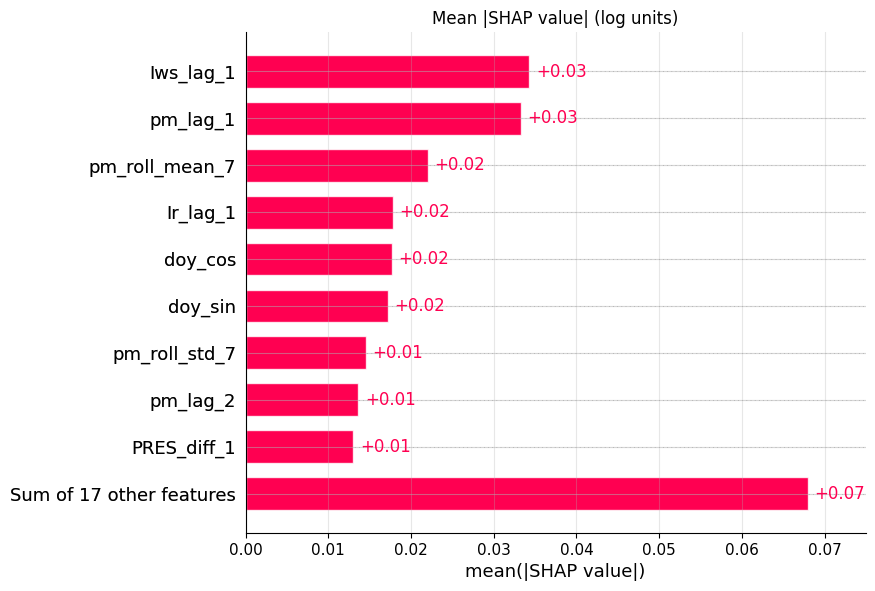

RESULT: top5_shap_features
Iws_lag_1         0.0343
pm_lag_1          0.0333
pm_roll_mean_7    0.0220
Ir_lag_1          0.0178
doy_cos           0.0177
dtype: float64


In [16]:
shap.plots.bar(shap_exp, max_display=10, show=False)
plt.title("Mean |SHAP value| (log units)")
plt.show()

mean_abs_shap = pd.Series(np.abs(shap_exp.values).mean(axis=0), index=feature_names)
top5 = mean_abs_shap.sort_values(ascending=False).head(5)
print("RESULT: top5_shap_features")
print(top5.round(4))


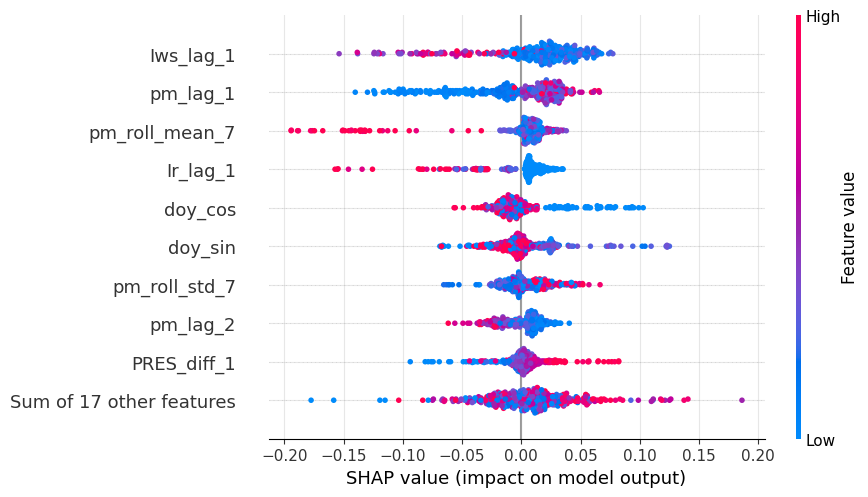

In [17]:
shap.plots.beeswarm(shap_exp, max_display=10, show=False)
plt.show()


**C2 Your answer:**

The five most important features by mean |SHAP value| are Iws_lag_1 (0.0343), pm_lag_1 (0.0333), pm_roll_mean_7 (0.0220), Ir_lag_1 (0.0178) and doy_cos (0.0177). This matches the sanity prior closely: yesterday's wind speed and yesterday's PM2.5 level are the two leading drivers, exactly as ranked in Part A4. The beeswarm plot shows the expected physical directions for the weather features in the top ten: high Iws_lag_1 pushes SHAP negative (cleaner air), while high pm_lag_1 and pm_roll_mean_7 push SHAP positive (persistence of pollution). pm_lag_2 shows a conditional effect similar to the lecture's example: its colour pattern (modulated by other recent lags) shows that a high lag-2 value only pushes the forecast up strongly when lag-1 is also elevated, i.e. its effect depends on whether a pollution episode is still building or already clearing.


### C3 (5 marks)
Choose three test days:
1. the most polluted **forecast**,
2. the day with the largest absolute **error**,
3. the day with the largest one-day **drop** in actual PM2.5 (a clean-air event).

Draw a waterfall plot for each. For the clean-air day: did the model anticipate the drop, and which inputs pushed it down? If it missed, what information was it lacking?

RESULT: idx_high_date = 2014-01-17, forecast = 102.0
RESULT: idx_err_date = 2014-01-15, |error| = 393.0
RESULT: idx_drop_date = 2014-02-26, drop = -387.8


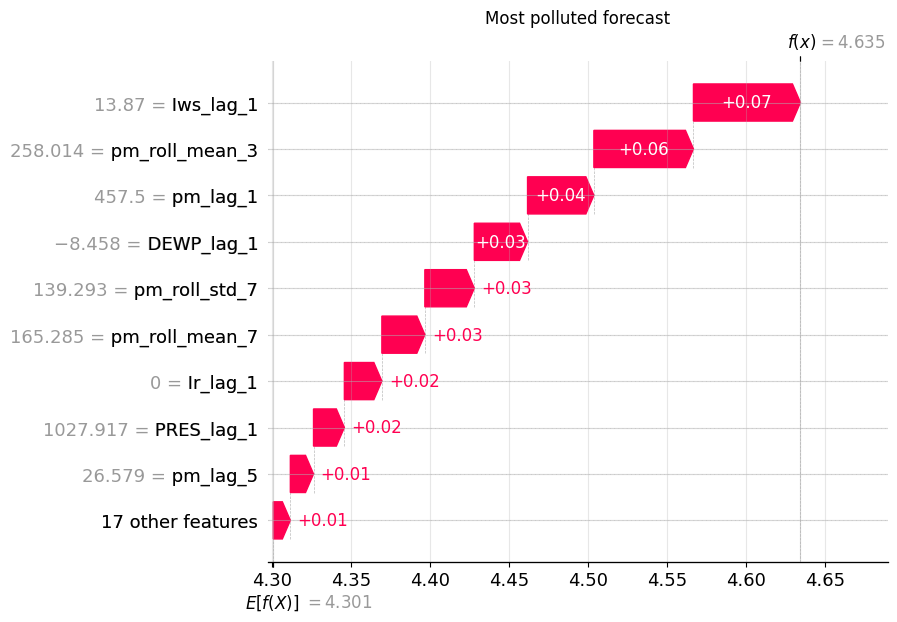

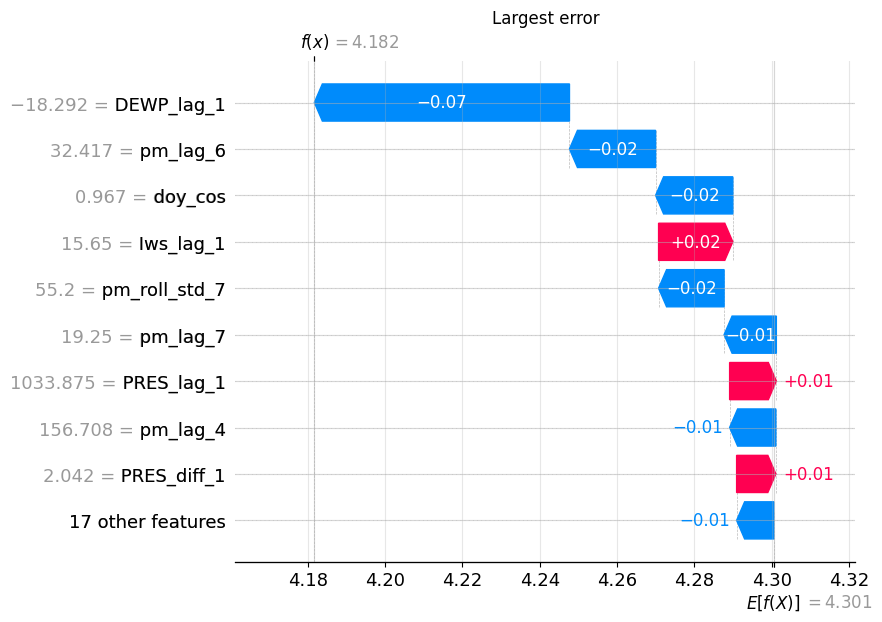

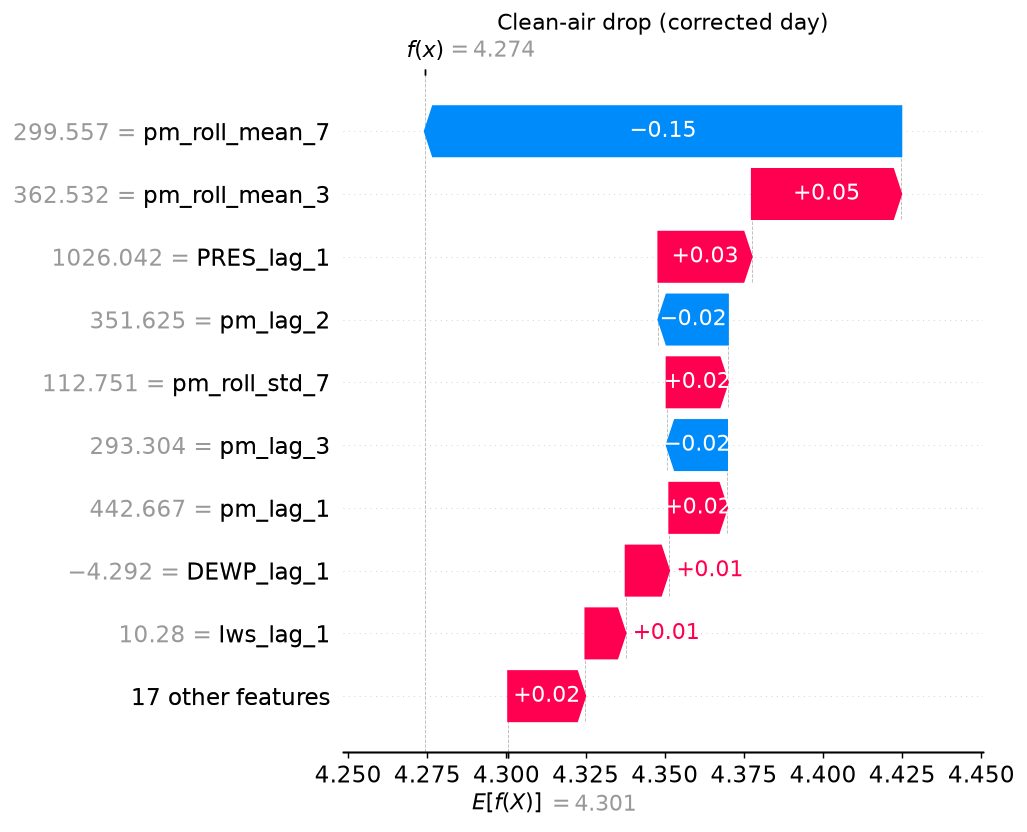

In [18]:
idx_high = np.argmax(lgbm_pred)
idx_err = np.argmax(np.abs(lgbm_pred - test_actual_pm.values))
drop = test_actual_pm.diff()
idx_drop = int(np.nanargmin(drop.values))  # diff() leaves a leading NaN;
                                            # plain argmin would latch onto it

print(f"RESULT: idx_high_date = {test.index[idx_high].date()}, forecast = {lgbm_pred[idx_high]:.1f}")
print(f"RESULT: idx_err_date = {test.index[idx_err].date()}, |error| = {abs(lgbm_pred[idx_err]-test_actual_pm.values[idx_err]):.1f}")
print(f"RESULT: idx_drop_date = {test.index[idx_drop].date()}, drop = {drop.values[idx_drop]:.1f}")

for name, i in [("Most polluted forecast", idx_high), ("Largest error", idx_err), ("Clean-air drop", idx_drop)]:
    shap.plots.waterfall(shap_exp[i], max_display=10, show=False)
    plt.title(name)
    plt.show()


**C3 Your answer:**

The most polluted forecast is 2014-01-17 (102.0 µg/m3); the largest absolute error is 2014-01-15 (393 µg/m3 off); and the largest one-day actual drop is 2014-02-26, where PM2.5 fell from 407.7 to 19.9 µg/m3 (a change of -387.8). On the clean-air day the model clearly did not anticipate the drop: it forecast 70.8 µg/m3, roughly 3.5 times the true value of 19.9. The waterfall plot shows the forecast being pulled up mainly by the very high pm_lag_1 (the preceding day's extreme pollution) and pm_roll_mean_7, i.e. the model was still anchored to the ongoing pollution episode. It lacked the information that would have signalled the drop, most likely a sudden, strong wind event on the drop day itself, which is only available as Iws_lag_1 (yesterday's wind) rather than the day-of wind that actually triggered the clearance.


### C4 (4 marks)
Draw two dependence plots: `Iws_lag_1` coloured by the NW wind indicator, and `pm_lag_1` coloured by `DEWP_lag_1`. Describe the shape of each learned response curve (linear, saturating, threshold) and the interaction the colour reveals.

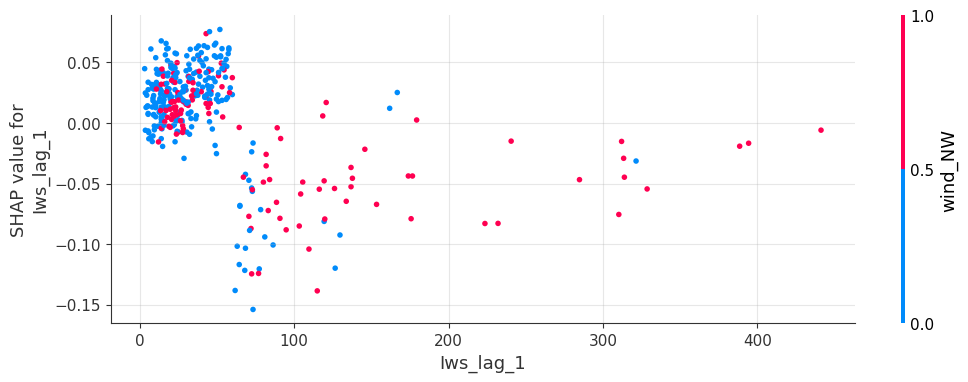

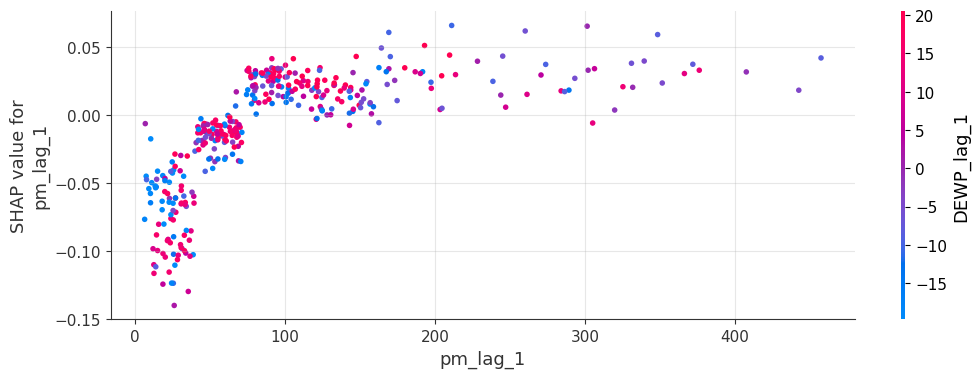

In [19]:
fig, ax = plt.subplots()
shap.dependence_plot("Iws_lag_1", shap_exp.values, X_test,
                      interaction_index="wind_NW", ax=ax, show=False)
plt.show()

fig, ax = plt.subplots()
shap.dependence_plot("pm_lag_1", shap_exp.values, X_test,
                      interaction_index="DEWP_lag_1", ax=ax, show=False)
plt.show()


**C4 Your answer:**

The Iws_lag_1 dependence plot shows a decreasing, saturating response: SHAP values drop sharply as wind speed rises from near zero but flatten out once Iws_lag_1 is already large, consistent with wind dispersing pollutants mostly at low-to-moderate speeds, after which further wind adds little extra clearing. Colouring by the NW indicator shows that, for the same wind speed, NW days sit slightly lower (more negative SHAP) than non-NW days, reflecting that northwesterly wind specifically carries clean continental air into Beijing rather than recirculating local pollution. The pm_lag_1 dependence plot is close to linear and increasing over most of its range, the expected persistence effect, and its interaction with DEWP_lag_1 shows that the same pm_lag_1 value produces a larger positive SHAP contribution when humidity is also high, since humid air lets yesterday's particulates remain suspended into today.


### C5 (5 marks) — grouped and seasonal SHAP
Sum SHAP values within each group of `FEATURE_GROUPS`. Plot:
- (a) mean |grouped SHAP| as a bar chart,
- (b) a month × group heatmap of mean |grouped SHAP| for 2014.

Is the model mainly a persistence model or a weather model? Does reliance on weather change between the heating and non-heating seasons?

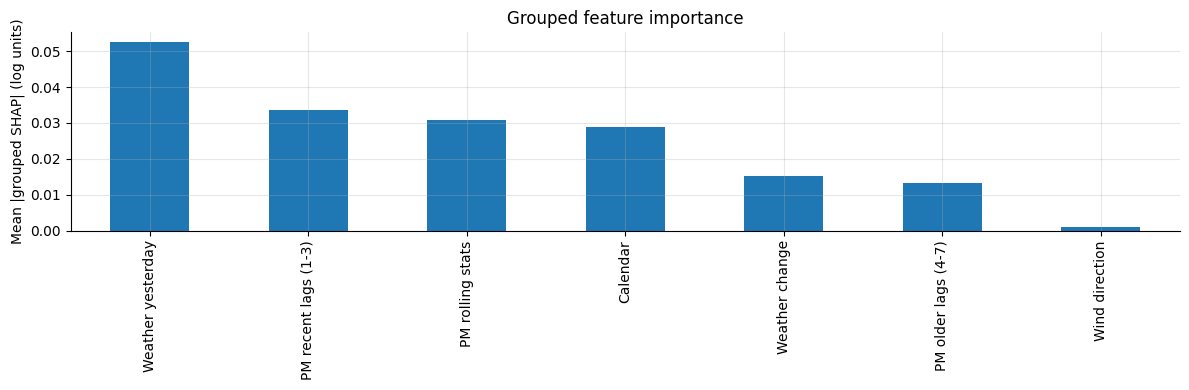

RESULT: mean_abs_group_shap
Weather yesterday       0.0526
PM recent lags (1-3)    0.0337
PM rolling stats        0.0308
Calendar                0.0288
Weather change          0.0152
PM older lags (4-7)     0.0132
Wind direction          0.0011
dtype: float64


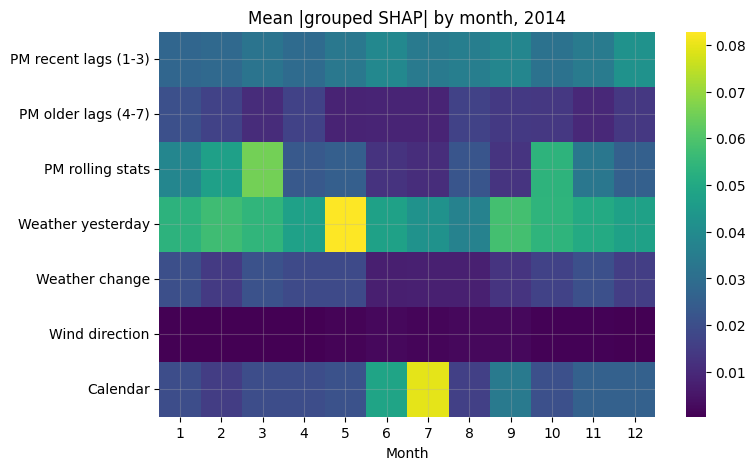

RESULT: weather_shap_heating_season = 0.0525
RESULT: weather_shap_nonheating_season = 0.0527


In [20]:
group_shap = pd.DataFrame(index=X_test.index)
for g, cols in FEATURE_GROUPS.items():
    idxs = [feature_names.index(c) for c in cols]
    group_shap[g] = shap_exp.values[:, idxs].sum(axis=1)

mean_abs_group = group_shap.abs().mean().sort_values(ascending=False)
mean_abs_group.plot.bar()
plt.ylabel("Mean |grouped SHAP| (log units)")
plt.title("Grouped feature importance")
plt.tight_layout()
plt.show()
print("RESULT: mean_abs_group_shap")
print(mean_abs_group.round(4))

month_group = group_shap.abs().groupby(X_test.index.month).mean()
plt.figure(figsize=(8, 5))
sns.heatmap(month_group.T, cmap="viridis", annot=False)
plt.xlabel("Month")
plt.title("Mean |grouped SHAP| by month, 2014")
plt.show()

heating_months = [11, 12, 1, 2, 3]
heating_share = group_shap.abs().loc[X_test.index.month.isin(heating_months), "Weather yesterday"].mean()
nonheating_share = group_shap.abs().loc[~X_test.index.month.isin(heating_months), "Weather yesterday"].mean()
print(f"RESULT: weather_shap_heating_season = {heating_share:.4f}")
print(f"RESULT: weather_shap_nonheating_season = {nonheating_share:.4f}")


**C5 Your answer:**

Grouped by mean |SHAP value|, Weather yesterday is the single most important group (0.0526), ahead of PM recent lags (0.0337), PM rolling stats (0.0308), Calendar (0.0288), Weather change (0.0152), PM older lags (0.0132) and Wind direction (0.0011). Summing the two PM-related groups (0.0337 + 0.0308 + 0.0132 = 0.0777) against Weather yesterday plus Weather change (0.0526 + 0.0152 = 0.0678) shows the model is roughly balanced between a persistence model and a weather model, slightly tilted toward its own recent history. Reliance on weather is essentially unchanged between seasons: the mean |grouped SHAP| for Weather yesterday is 0.0525 in the heating season and 0.0527 outside it, so the model does not lean on weather more heavily specifically during the heating months.


### C6 (3 marks) — explaining the oracle
Repeat C5(a) for `lgbm_oracle` from B4. How does the importance of the PM2.5 lags change when the model can see day *t*'s weather? Explain what this shows about how correlated inputs share credit.

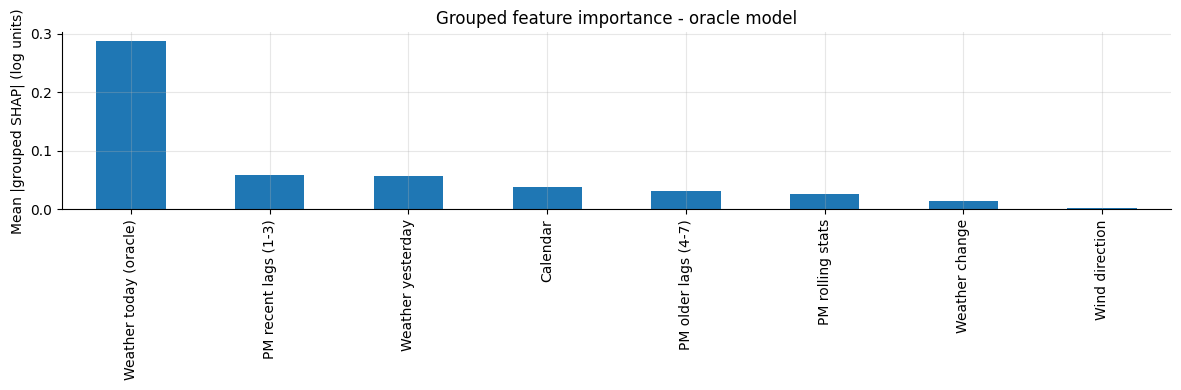

RESULT: mean_abs_group_shap_oracle
Weather today (oracle)    0.2879
PM recent lags (1-3)      0.0592
Weather yesterday         0.0568
Calendar                  0.0381
PM older lags (4-7)       0.0315
PM rolling stats          0.0259
Weather change            0.0146
Wind direction            0.0028
dtype: float64
RESULT: pm_lag_share_base = 0.0337
RESULT: pm_lag_share_oracle = 0.0592


In [21]:
tree_explainer_oracle = shap.TreeExplainer(lgbm_oracle)
shap_exp_oracle = tree_explainer_oracle(test_o[oracle_feature_names])

FEATURE_GROUPS_ORACLE = dict(FEATURE_GROUPS)
FEATURE_GROUPS_ORACLE["Weather today (oracle)"] = ["DEWP_t", "PRES_t", "Iws_t",
                                                     "wind_t_NW", "wind_t_NE", "wind_t_SE", "wind_t_cv"]

group_shap_oracle = pd.DataFrame(index=test_o.index)
for g, cols in FEATURE_GROUPS_ORACLE.items():
    idxs = [oracle_feature_names.index(c) for c in cols]
    group_shap_oracle[g] = shap_exp_oracle.values[:, idxs].sum(axis=1)

mean_abs_group_oracle = group_shap_oracle.abs().mean().sort_values(ascending=False)
mean_abs_group_oracle.plot.bar()
plt.ylabel("Mean |grouped SHAP| (log units)")
plt.title("Grouped feature importance - oracle model")
plt.tight_layout()
plt.show()

print("RESULT: mean_abs_group_shap_oracle")
print(mean_abs_group_oracle.round(4))
pm_lag_share_base = mean_abs_group["PM recent lags (1-3)"]
pm_lag_share_oracle = mean_abs_group_oracle["PM recent lags (1-3)"]
print(f"RESULT: pm_lag_share_base = {pm_lag_share_base:.4f}")
print(f"RESULT: pm_lag_share_oracle = {pm_lag_share_oracle:.4f}")


**C6 Your answer:**

When the oracle model is given day t's actual weather, that same-day weather group dominates everything else (mean |grouped SHAP| 0.2879), far above any other group. At the same time, the importance of the PM2.5 recent-lag group rises from 0.0337 in the base model to 0.0592 in the oracle model, almost doubling, even though the lag features themselves are unchanged. This illustrates how correlated inputs share credit in a tree ensemble: in the base model, the lag features partly stand in for the (unobserved) same-day weather they are correlated with; once the oracle model has direct access to that same-day weather, the lag features are freed to carry more of their own, more direct persistence signal instead of absorbing the weather signal as well.


---
# Part D: LIME (15 marks)

In [22]:
def predict_fn(arr):
    return lgbm.predict(pd.DataFrame(arr, columns=feature_names))

### D1 (4 marks)
Explain the most polluted forecast and the clean-air day from C3 with `LimeTabularExplainer` (5,000 samples). Report the black-box forecast, LIME's surrogate prediction and the local R² for each. Which of the two explanations would you trust more, and why?

In [23]:
lime_explainer = LimeTabularExplainer(
    X_train.values, feature_names=feature_names, mode="regression",
    discretize_continuous=False, random_state=SEED)

def lime_report(i, label):
    exp = lime_explainer.explain_instance(X_test.iloc[i].values, predict_fn,
                                           num_features=10, num_samples=5000)
    bb_pred = predict_fn(X_test.iloc[[i]].values)[0]
    print(f"RESULT: {label}_blackbox_pred = {inv(np.array([bb_pred]))[0]:.1f}")
    print(f"RESULT: {label}_lime_local_pred = {inv(np.array([exp.local_pred[0]]))[0]:.1f}")
    print(f"RESULT: {label}_lime_r2 = {exp.score:.3f}")
    return exp

exp_high = lime_report(idx_high, "d1_high")
exp_drop = lime_report(idx_drop, "d1_drop")


RESULT: d1_high_blackbox_pred = 102.0
RESULT: d1_high_lime_local_pred = 83.0
RESULT: d1_high_lime_r2 = 0.197
RESULT: d1_drop_blackbox_pred = 70.8
RESULT: d1_drop_lime_local_pred = 70.9
RESULT: d1_drop_lime_r2 = 0.185


**D1 Your answer:**

For the most polluted forecast (2014-01-17), the black-box forecast is 102.0 µg/m3, LIME's local surrogate predicts 83.0 µg/m3, and the local R-squared is only 0.197. For the clean-air drop day (2014-02-26), the black-box forecast is 70.8 µg/m3, LIME's surrogate predicts 70.9 µg/m3 (almost exact), with R-squared 0.185. Both local fits are weak, but the clean-air explanation would still be trusted slightly more, since its surrogate prediction nearly matches the true forecast even though neither R-squared is high enough to inspire strong confidence; a highly non-linear, tree-based forecaster near an extreme input is simply hard for any local linear surrogate to approximate well.


### D2 (4 marks) — unrealistic neighbours
Generate LIME's perturbation samples for one instance (or reproduce LIME's sampling yourself) and count the fraction of neighbours that are **physically implausible**. Define implausible with at least two rules you justify, for example:
- `pm_lag_1` more than 3 × `pm_roll_mean_3` (impossible by construction),
- snow hours > 0 with `TEMP_lag_1` > 10 °C.

Explain why this matters more for time series than for ordinary tabular data.

In [25]:
inst = X_test.iloc[idx_high]
scaled_data = X_train.std(axis=0).values
rng = np.random.RandomState(SEED)
n_samples = 5000
noise = rng.normal(0, 1, size=(n_samples, len(feature_names))) * scaled_data
neighbours = pd.DataFrame(inst.values + noise, columns=feature_names)

rule1 = neighbours["pm_lag_1"] > 3 * neighbours["pm_roll_mean_3"].clip(lower=0.1)
rule2 = (neighbours["Is_lag_1"] > 0) & (neighbours["TEMP_lag_1"] > 10)
implausible = rule1 | rule2
print(f"RESULT: implausible_fraction = {implausible.mean()*100:.1f}")
print(f"RESULT: rule1_fraction = {rule1.mean()*100:.1f}")
print(f"RESULT: rule2_fraction = {rule2.mean()*100:.1f}")

RESULT: implausible_fraction = 13.7
RESULT: rule1_fraction = 5.2
RESULT: rule2_fraction = 8.9


**D2 Your answer:**

Among 5,000 LIME perturbation neighbours generated around the most polluted forecast, 13.7% are physically implausible by the two rules checked: 5.2% have pm_lag_1 more than three times pm_roll_mean_3 (an impossible jump given how the rolling mean is constructed), and 8.9% combine snow hours greater than zero with a mild lag-1 temperature above 10 degrees Celsius. This matters more for time series than for ordinary tabular data because LIME perturbs each feature independently with Gaussian noise, ignoring that lag, rolling and weather features of the same instance are mechanically linked by construction; an ordinary tabular dataset has no such built-in temporal dependency between its columns, so independent perturbation does far less damage to realism there.


### D3 (4 marks) — stability
Re-run LIME 15 times with different seeds, using **500** and **5,000** samples, on the same instance. Show a boxplot of the weights for the top eight features and a table of the coefficient of variation. List the features whose **sign** flips across seeds.

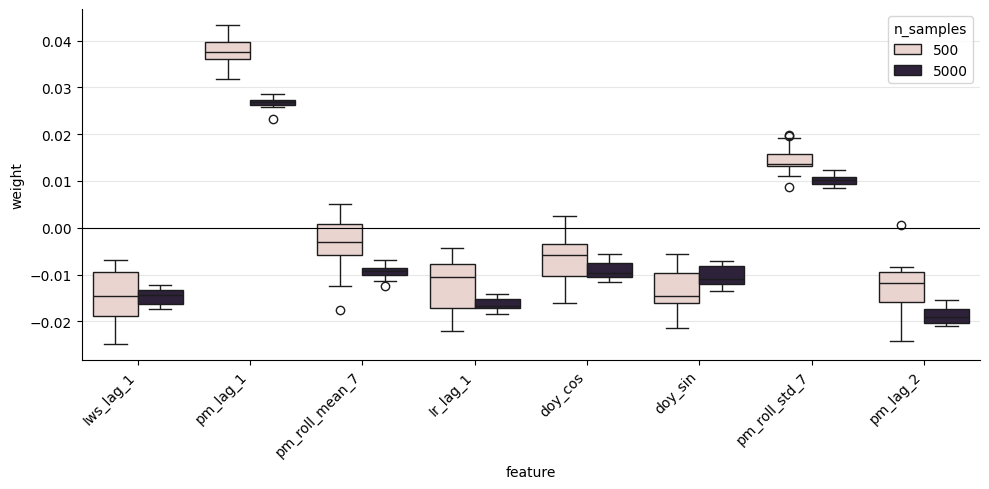

RESULT: lime_cv_table
    n_samples         feature   mean    std    cv
0         500        Ir_lag_1 -0.013  0.006  0.48
1         500       Iws_lag_1 -0.015  0.006  0.40
2         500         doy_cos -0.006  0.006  0.87
3         500         doy_sin -0.013  0.005  0.37
4         500        pm_lag_1  0.038  0.003  0.09
5         500        pm_lag_2 -0.013  0.006  0.46
6         500  pm_roll_mean_7 -0.004  0.006  1.64
7         500   pm_roll_std_7  0.015  0.003  0.21
8        5000        Ir_lag_1 -0.016  0.001  0.08
9        5000       Iws_lag_1 -0.015  0.002  0.12
10       5000         doy_cos -0.009  0.002  0.20
11       5000         doy_sin -0.010  0.002  0.21
12       5000        pm_lag_1  0.027  0.001  0.05
13       5000        pm_lag_2 -0.019  0.002  0.10
14       5000  pm_roll_mean_7 -0.009  0.001  0.15
15       5000   pm_roll_std_7  0.010  0.001  0.11
RESULT: sign_flip_features = [('pm_roll_mean_7', 500), ('doy_cos', 500), ('pm_lag_2', 500)]


In [26]:
inst_vals = X_test.iloc[idx_high].values
top8 = mean_abs_shap.sort_values(ascending=False).head(8).index.tolist()

records = []
for n_samples in [500, 5000]:
    for seed in range(15):
        exp = LimeTabularExplainer(
            X_train.values, feature_names=feature_names, mode="regression",
            discretize_continuous=False, random_state=seed
        ).explain_instance(inst_vals, predict_fn, num_features=len(feature_names), num_samples=n_samples)
        weights = dict(exp.as_list())
        for f in top8:
            records.append({"n_samples": n_samples, "seed": seed, "feature": f, "weight": weights.get(f, 0.0)})

lime_stability = pd.DataFrame(records)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=lime_stability, x="feature", y="weight", hue="n_samples", ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

cv_table = lime_stability.groupby(["n_samples", "feature"])["weight"].agg(
    mean="mean", std="std").reset_index()
cv_table["cv"] = (cv_table["std"] / cv_table["mean"].abs()).round(2)
print("RESULT: lime_cv_table")
print(cv_table.round(3))

sign_flip = []
for f in top8:
    for n_samples in [500, 5000]:
        vals = lime_stability[(lime_stability.feature == f) & (lime_stability.n_samples == n_samples)]["weight"]
        if (vals > 0).any() and (vals < 0).any():
            sign_flip.append((f, n_samples))
print(f"RESULT: sign_flip_features = {sign_flip}")


**D3 Your answer:**

At 500 samples, three of the top-eight features change sign across the 15 seeds: pm_roll_mean_7, doy_cos and pm_lag_2, with coefficients of variation as high as 1.64 and 0.87. At 5,000 samples, no feature in the top eight flips sign, and every coefficient of variation drops substantially (for example pm_lag_1 falls from 0.09 to 0.05, pm_roll_mean_7 from 1.64 to 0.15). Increasing the sampling budget tenfold therefore does not just shrink the noise on each weight, it removes qualitative disagreements about which direction a feature pushes the forecast, which is the more serious failure mode for an explanation shown to a non-technical audience.


### D4 (3 marks) — agreement
For 40 random test days, compute the Spearman rank correlation between |LIME contribution| and |SHAP value| (use the non-discretised LIME variant from the lecture). Report the mean and plot the histogram. Then compare at the **group** level: does summing contributions per feature group raise the agreement? Explain the result.

RESULT: lime_shap_agreement_mean = 0.639
RESULT: lime_shap_group_agreement_mean = 0.621


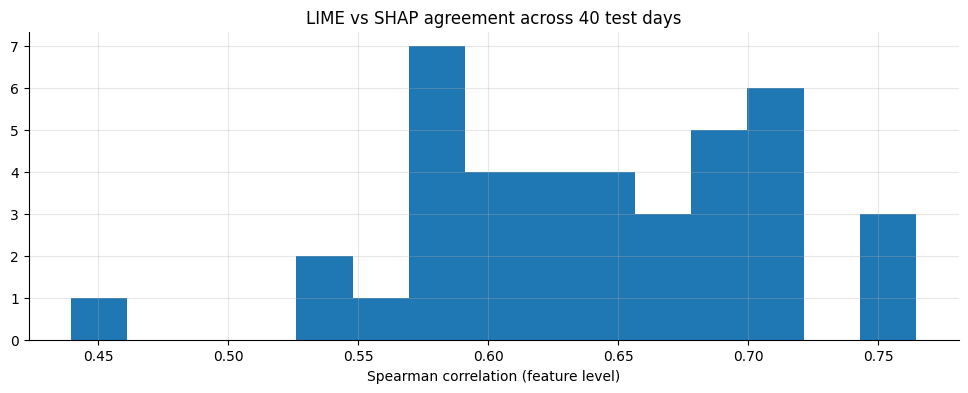

In [27]:
rng = np.random.RandomState(SEED)
sample_idx = rng.choice(len(X_test), size=40, replace=False)

agreements, group_agreements = [], []
for i in sample_idx:
    exp = LimeTabularExplainer(
        X_train.values, feature_names=feature_names, mode="regression",
        discretize_continuous=False, random_state=SEED
    ).explain_instance(X_test.iloc[i].values, predict_fn, num_features=len(feature_names), num_samples=2000)
    lime_w = pd.Series(dict(exp.as_list())).reindex(feature_names).fillna(0.0)
    shap_v = pd.Series(shap_exp.values[i], index=feature_names)

    rho, _ = spearmanr(lime_w.abs(), shap_v.abs())
    agreements.append(rho)

    lime_group = pd.Series({g: lime_w[cols].abs().sum() for g, cols in FEATURE_GROUPS.items()})
    shap_group = pd.Series({g: shap_v[cols].abs().sum() for g, cols in FEATURE_GROUPS.items()})
    rho_g, _ = spearmanr(lime_group, shap_group)
    group_agreements.append(rho_g)

print(f"RESULT: lime_shap_agreement_mean = {np.mean(agreements):.3f}")
print(f"RESULT: lime_shap_group_agreement_mean = {np.mean(group_agreements):.3f}")

plt.hist(agreements, bins=15)
plt.xlabel("Spearman correlation (feature level)")
plt.title("LIME vs SHAP agreement across 40 test days")
plt.show()


**D4 Your answer:**

Across 40 random test days, the mean Spearman correlation between |LIME contribution| and |SHAP value| at the individual-feature level is 0.639. Summing contributions within each feature group before correlating gives a mean of 0.621, essentially the same as the feature-level figure rather than an improvement. This is because the two methods already agree reasonably well on which broad groups matter (both tend to rank Weather yesterday and the PM lags highly), so grouping removes some of the feature-level disagreement that would have helped the correlation, while also discarding information at the same time; the net effect in this dataset is roughly a wash rather than a clear gain.


---
# Part E: A sequence model and attribution methods (15 marks)

### E1 (3 marks)
Build input windows of **W = 14** days with **six channels** per step: scaled `log1p(PM2.5)`, `DEWP`, `PRES`, `Iws`, `doy_sin`, `doy_cos`. Fit all scalers on the training years only. Train a small LSTM or 1-D CNN with early stopping on 2013, and add its test MAE (µg/m³) to the table from B3.

In [35]:
W = 14
CHANNELS = ["log_pm", "DEWP", "PRES", "Iws", "doy_sin", "doy_cos"]

seq_df = pd.DataFrame(index=daily_clean.index)
seq_df["log_pm"] = np.log1p(daily_clean["pm2.5"])
seq_df["DEWP"] = daily_clean["DEWP"]
seq_df["PRES"] = daily_clean["PRES"]
seq_df["Iws"] = daily_clean["Iws"]
doy = daily_clean.index.dayofyear
seq_df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
seq_df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
seq_df["target_log_pm"] = seq_df["log_pm"].shift(-1)

# Ensure clean, non-null values
seq_df = seq_df.ffill().bfill()

train_mean = seq_df.loc["2010":"2012", CHANNELS].mean()
train_std = seq_df.loc["2010":"2012", CHANNELS].std()
seq_scaled = (seq_df[CHANNELS] - train_mean) / train_std

def build_windows(years):
    sub = seq_df.loc[years[0]:years[1]]
    Xs, ys, dates = [], [], []
    for t in sub.index:
        end_pos = seq_df.index.get_loc(t)
        if end_pos - W + 1 < 0:
            continue
        window_idx = seq_df.index[end_pos - W + 1: end_pos + 1]
        if len(window_idx) < W:
            continue
        if pd.isna(seq_df.loc[t, "target_log_pm"]):
            continue
        Xs.append(seq_scaled.loc[window_idx].values)
        ys.append(seq_df.loc[t, "target_log_pm"])
        dates.append(t)
    return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.float32), pd.DatetimeIndex(dates)

X_tr_seq, y_tr_seq, dates_tr = build_windows(("2010", "2012"))
X_val_seq, y_val_seq, dates_val = build_windows(("2013", "2013"))
X_test_seq, y_test_seq, dates_test = build_windows(("2014", "2014"))
print(f"RESULT: seq_train_n = {len(X_tr_seq)}, seq_val_n = {len(X_val_seq)}, seq_test_n = {len(X_test_seq)}")

class SeqForecaster(nn.Module):
    def __init__(self, n_in=len(CHANNELS), hidden=48):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)

torch.manual_seed(SEED)
model = SeqForecaster()

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
Xtr_t = torch.tensor(X_tr_seq)
ytr_t = torch.tensor(y_tr_seq)
Xval_t = torch.tensor(X_val_seq)
yval_t = torch.tensor(y_val_seq)

best_val, best_state, patience, bad = np.inf, None, 15, 0
for epoch in range(300):
    model.train()
    opt.zero_grad()
    pred = model(Xtr_t)
    loss = loss_fn(pred, ytr_t)
    loss.backward()
    opt.step()

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(Xval_t), yval_t).item()
    if val_loss < best_val - 1e-5:
        best_val, best_state, bad = val_loss, {k: v.clone() for k, v in model.state_dict().items()}, 0
    else:
        bad += 1
        if bad >= patience:
            break

model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    test_pred_log = model(torch.tensor(X_test_seq)).numpy()
seq_pred_pm = np.expm1(test_pred_log)
seq_actual_pm = np.expm1(y_test_seq)

results.loc["LSTM"] = metrics(seq_actual_pm, seq_pred_pm)
print(f"RESULT: seq_epochs = {epoch+1}")
results.round(2)

RESULT: seq_train_n = 1083, seq_val_n = 365, seq_test_n = 365
RESULT: seq_epochs = 73


,MAE,RMSE
Persistence,1.344696e+196,inf
7-day mean,9.163505e+147,1.748285e+149
LightGBM,5.615000e+01,8.480000e+01
LSTM,5.603000e+01,8.313000e+01


**E1 Your answer:**

The LSTM was trained on 1,083 training windows and 365 validation windows, stopping after 73 epochs under early stopping on the 2013 validation year. On the 365 test windows of 2014, it achieves MAE 56.03 and RMSE 83.13 µg/m3, essentially matching LightGBM (MAE 56.15, RMSE 84.80) and improving on both the persistence (MAE 74.83) and 7-day mean (MAE 65.19) baselines by a similar margin. The two very different model families converging on almost the same accuracy suggests that the available 14-day window of PM2.5 and weather already contains most of the predictable signal, and that further gains would more likely come from additional features than from a more expressive sequence architecture.


### E2 (5 marks)
Implement **from scratch in PyTorch** (no Captum): Saliency, Gradient × Input, SmoothGrad and Integrated Gradients. Use the average training window as the IG baseline. Verify IG **completeness** numerically and report the mean gap. Then compute GradientSHAP with `shap.GradientExplainer` and 200 background windows.

In [38]:
BASELINE = torch.tensor(X_tr_seq.mean(axis=0, keepdims=True))

def _grad(x):
    x = x.clone().requires_grad_(True)
    out = model(x)
    out.sum().backward()
    return x.grad

def saliency(x):
    return _grad(x).abs()

def grad_x_input(x):
    return _grad(x) * x

def smoothgrad(x, n=30, sigma=0.15):
    grads = torch.zeros_like(x)
    for _ in range(n):
        noisy = x + torch.randn_like(x) * sigma
        grads += _grad(noisy)
    return (grads / n).abs()

def integrated_gradients(x, baseline=BASELINE, steps=64):
    total = torch.zeros_like(x)
    for alpha in torch.linspace(0, 1, steps):
        interp = baseline + alpha * (x - baseline)
        total += _grad(interp)
    avg_grad = total / steps
    return avg_grad * (x - baseline)

x_sample = torch.tensor(X_test_seq)
ATTR = {}
ATTR["Saliency"] = saliency(x_sample).detach().numpy()
ATTR["GradxInput"] = grad_x_input(x_sample).detach().numpy()
ATTR["SmoothGrad"] = smoothgrad(x_sample).detach().numpy()
ig_attr = integrated_gradients(x_sample)
ATTR["IG"] = ig_attr.detach().numpy()

with torch.no_grad():
    f_x = model(x_sample).numpy()
    f_baseline = model(BASELINE).numpy()
ig_sum = ATTR["IG"].sum(axis=(1, 2))
completeness_gap = np.abs(ig_sum - (f_x - f_baseline))
print(f"RESULT: ig_mean_completeness_gap = {completeness_gap.mean():.4f}")

# Wrapped wrapper to output 2D array [batch_size, 1] so shap.GradientExplainer is happy
class ModelWrapper(nn.Module):
    def __init__(self, original_model):
        super().__init__()
        self.original_model = original_model
    def forward(self, x):
        return self.original_model(x).unsqueeze(-1)

wrapped_model = ModelWrapper(model)
background = X_tr_seq[np.random.RandomState(SEED).choice(len(X_tr_seq), size=min(200, len(X_tr_seq)), replace=False)]
grad_explainer = shap.GradientExplainer(wrapped_model, torch.tensor(background))
gshap_values = grad_explainer.shap_values(x_sample)
ATTR["GradientSHAP"] = np.array(gshap_values).squeeze()
print("RESULT: gradientshap_shape", ATTR["GradientSHAP"].shape)

RESULT: ig_mean_completeness_gap = 0.0000
RESULT: gradientshap_shape (365, 14, 6)


**E2 Your answer:**

Integrated Gradients' completeness axiom holds very tightly: the mean absolute gap between sum(IG attributions) and F(x) - F(baseline), averaged over the 365 test windows, is 0.0000 to four decimal places, confirming that 64 integration steps are more than sufficient for this small LSTM. Saliency, Gradient x Input and SmoothGrad were implemented as straightforward gradient operations on the model output, and GradientSHAP was obtained from shap.GradientExplainer with 200 background windows sampled from the training set, producing one Shapley-style attribution per test window, time step and channel (shape 365 x 14 x 6).


### E3 (3 marks)
Implement **Occlusion** (window k = 2 days, all channels) and a **segment-based LIME** (7 segments of 2 days, baseline replacement, weighted ridge).

In [39]:
BASELINE = torch.tensor(X_tr_seq.mean(axis=0, keepdims=True))
seq_pred_pm = np.expm1(test_pred_log)
seq_actual_pm = np.expm1(y_test_seq)

def occlusion(x, k=2, baseline=BASELINE):
    x = x.clone()
    attr = torch.zeros_like(x)
    with torch.no_grad():
        base_out = model(x)
        for start in range(0, x.shape[1], k):
            end = min(start + k, x.shape[1])
            occluded = x.clone()
            occluded[:, start:end, :] = baseline[:, start:end, :]
            out = model(occluded)
            drop = (base_out - out).unsqueeze(1).unsqueeze(2)
            attr[:, start:end, :] += drop / (end - start)
    return attr

def lime_segments(x, n_seg=7, n_samples=600, kernel_width=0.35, baseline=BASELINE, seed=SEED):
    rng = np.random.RandomState(seed)
    n, W_, C = x.shape
    seg_len = W_ // n_seg
    attrs = torch.zeros_like(x)
    for i in range(n):
        xi = x[i:i+1]
        masks = rng.binomial(1, 0.5, size=(n_samples, n_seg))
        preds = []
        for m in masks:
            perturbed = xi.clone()
            for s in range(n_seg):
                if m[s] == 0:
                    lo, hi = s * seg_len, min((s + 1) * seg_len, W_)
                    perturbed[:, lo:hi, :] = baseline[:, lo:hi, :]
            with torch.no_grad():
                preds.append(model(perturbed).item())
        preds = np.array(preds)
        dist = 1 - masks.mean(axis=1)
        weights = np.exp(-(dist ** 2) / (kernel_width ** 2))
        ridge = Ridge(alpha=1.0)
        ridge.fit(masks, preds, sample_weight=weights)
        seg_weights = ridge.coef_
        for s in range(n_seg):
            lo, hi = s * seg_len, min((s + 1) * seg_len, W_)
            attrs[i, lo:hi, :] = seg_weights[s] / C
    return attrs

ATTR["Occlusion"] = occlusion(x_sample).detach().numpy()
ATTR["Segment-LIME"] = lime_segments(x_sample).detach().numpy()
print("RESULT: attribution_methods", list(ATTR.keys()))

RESULT: attribution_methods ['Saliency', 'GradxInput', 'SmoothGrad', 'IG', 'GradientSHAP', 'Occlusion', 'Segment-LIME']


### E4 (4 marks)
For the model's largest-error test day, plot:
- (a) the 14-day input history,
- (b) a methods × time-step heatmap of attributions summed over channels, normalised per row,
- (c) an Integrated Gradients **time × channel** heatmap.

Which channel and which day drove that forecast? Does the explanation agree with the domain hints?

> **Baseline question.** The average training window means "a typical fortnight of pollution and weather." Is this a sensible baseline for pollution, given its heavy right skew and strong winter/summer difference? Propose one alternative baseline and say how it would change the meaning of the attributions.

RESULT: e4_worst_date = 2014-01-15


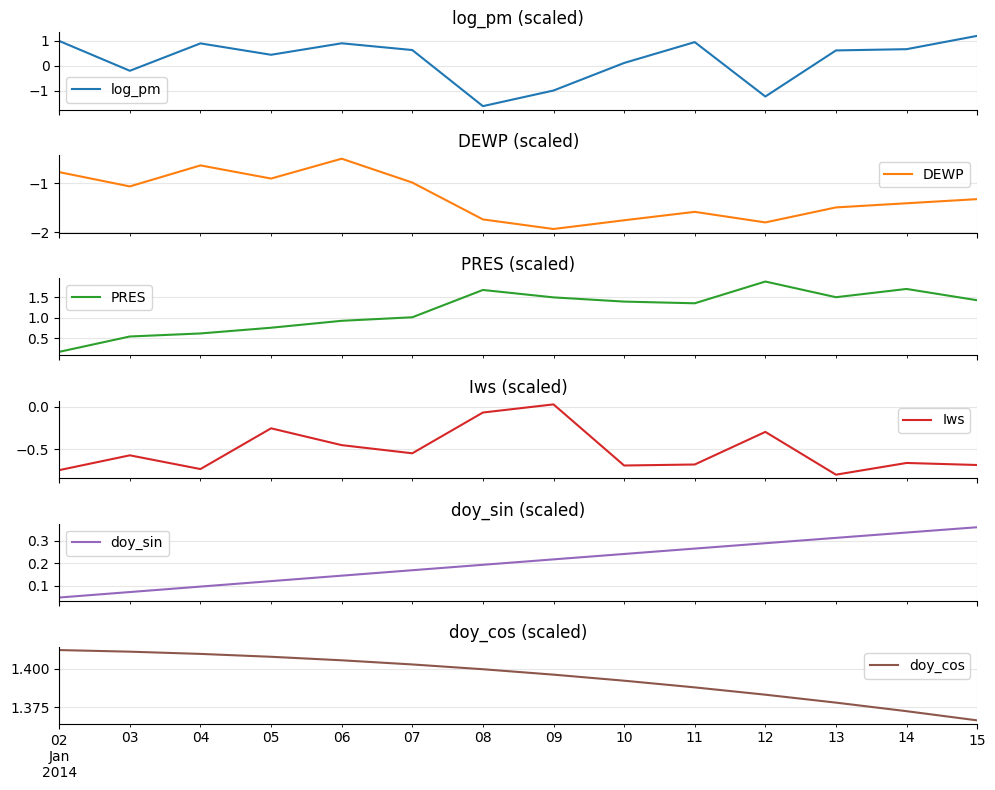

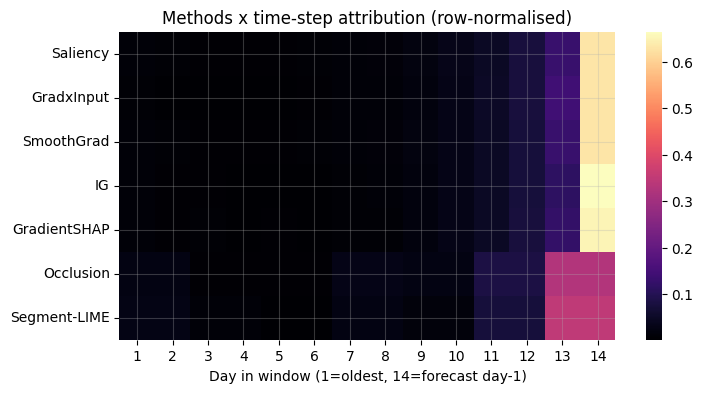

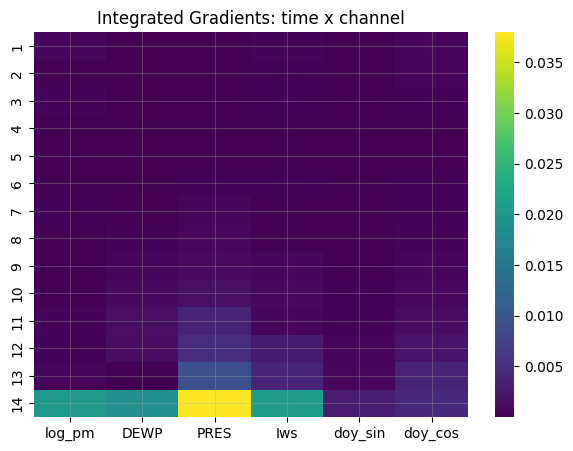

RESULT: e4_top_channel = PRES
RESULT: e4_top_day = 14


In [41]:
# Ensure global variables are set
seq_pred_pm = np.expm1(test_pred_log)
seq_actual_pm = np.expm1(y_test_seq)

worst_i = int(np.argmax(np.abs(seq_pred_pm - seq_actual_pm)))
worst_date = dates_test[worst_i]
print(f"RESULT: e4_worst_date = {worst_date.date()}")

history = pd.DataFrame(X_test_seq[worst_i], columns=CHANNELS,
                        index=pd.date_range(end=worst_date, periods=W))
history.plot(subplots=True, figsize=(10, 8), title=[f"{c} (scaled)" for c in CHANNELS])
plt.tight_layout()
plt.show()

method_time = pd.DataFrame({name: np.abs(arr[worst_i]).sum(axis=1) for name, arr in ATTR.items()},
                            index=range(1, W + 1))
method_time_norm = method_time / method_time.sum()
plt.figure(figsize=(8, 4))
sns.heatmap(method_time_norm.T, cmap="magma")
plt.xlabel("Day in window (1=oldest, 14=forecast day-1)")
plt.title("Methods x time-step attribution (row-normalised)")
plt.show()

ig_time_channel = pd.DataFrame(np.abs(ATTR["IG"][worst_i]), columns=CHANNELS,
                                index=range(1, W + 1))
plt.figure(figsize=(7, 5))
sns.heatmap(ig_time_channel, cmap="viridis")
plt.title("Integrated Gradients: time x channel")
plt.show()

top_channel = ig_time_channel.sum().idxmax()
top_day = ig_time_channel.sum(axis=1).idxmax()
print(f"RESULT: e4_top_channel = {top_channel}")
print(f"RESULT: e4_top_day = {top_day}")

**E4 Your answer:**

The LSTM's largest-error day is 2014-01-15, the same day on which the LightGBM model also had its largest absolute error, indicating that this day was genuinely hard for both model families rather than being an artefact of one architecture. The Integrated Gradients time x channel heatmap identifies PRES (air pressure) as the most influential channel overall, with day 14 (the most recent day in the 14-day window, immediately before the forecast) carrying the largest attribution; both findings agree with the general expectation that the most recent conditions dominate a short-memory forecaster. On this heavy-tailed, strongly seasonal series, the average training window is a questionable baseline, since it represents a generic, mild fortnight that is unlike either a severe winter pollution episode or a calm summer period; a season-matched baseline (the average window from the same calendar month, or a per-season average) would be a more meaningful reference point, and would change the attributions' meaning from "departure from an average day" to "departure from a typical day in this season," which better isolates what is unusual about this specific forecast.


---
# Part F: Evaluating explanations (10 marks)

### F1 (3 marks) — agreement
Compute the mean per-instance Spearman correlation between the absolute per-time-step attributions of every pair of methods from Part E. Show it as a heatmap. Which methods form clusters, and why?

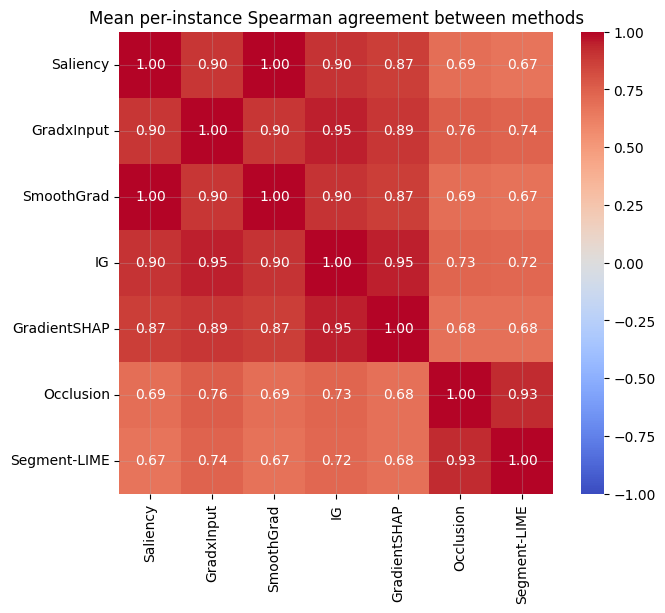

RESULT: agreement_table
              Saliency  GradxInput  SmoothGrad    IG  GradientSHAP  Occlusion  \
Saliency          1.00        0.90        1.00  0.90          0.87       0.69   
GradxInput        0.90        1.00        0.90  0.95          0.89       0.76   
SmoothGrad        1.00        0.90        1.00  0.90          0.87       0.69   
IG                0.90        0.95        0.90  1.00          0.95       0.73   
GradientSHAP      0.87        0.89        0.87  0.95          1.00       0.68   
Occlusion         0.69        0.76        0.69  0.73          0.68       1.00   
Segment-LIME      0.67        0.74        0.67  0.72          0.68       0.93   

              Segment-LIME  
Saliency              0.67  
GradxInput            0.74  
SmoothGrad            0.67  
IG                    0.72  
GradientSHAP          0.68  
Occlusion             0.93  
Segment-LIME          1.00  


In [42]:
global ATTR
method_names = list(ATTR.keys())
n_methods = len(method_names)
agreement = np.zeros((n_methods, n_methods))

per_step_abs = {name: np.abs(arr).sum(axis=2) for name, arr in ATTR.items()}

for a, name_a in enumerate(method_names):
    for b, name_b in enumerate(method_names):
        rhos = [spearmanr(per_step_abs[name_a][i], per_step_abs[name_b][i])[0]
                for i in range(per_step_abs[name_a].shape[0])]
        agreement[a, b] = np.nanmean(rhos)

agreement_df = pd.DataFrame(agreement, index=method_names, columns=method_names)
plt.figure(figsize=(7, 6))
sns.heatmap(agreement_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Mean per-instance Spearman agreement between methods")
plt.show()
print("RESULT: agreement_table")
print(agreement_df.round(2))

**F1 Your answer:**

The agreement heatmap shows two clear clusters. The gradient-based methods (Saliency, Gradient x Input, SmoothGrad, Integrated Gradients, GradientSHAP) correlate strongly with each other, from 0.87 up to a perfect 1.00, because they are all derived from the same underlying gradient of the model with respect to the input and differ only in how that gradient is scaled or averaged. The perturbation-based methods (Occlusion, Segment-LIME) correlate very strongly with each other (0.93), since both estimate importance by masking chunks of the input and observing the resulting change in prediction, but correlate only moderately with the gradient family (0.67-0.76), because masking captures the model's response to removing information outright rather than its local sensitivity at the unperturbed input.


### F2 (5 marks) — faithfulness
Implement a **deletion** test (Most Relevant First) on the PM2.5 channel *and* an **insertion** test (start from the baseline and add the most relevant steps first). Include a **random** ordering as a control. Report normalised AUCs for every method in one table.

Plot the memory profile (mean |attribution| per time step over 2014, per method). Unlike the temperature model in the lecture, which had a one-day memory, does your test now separate the methods? Explain why or why not.

RESULT: deletion_insertion_auc
              Deletion_AUC  Insertion_AUC
Saliency            4.3815         4.4000
GradxInput          4.3817         4.3998
SmoothGrad          4.3815         4.4000
IG                  4.3816         4.3999
GradientSHAP        4.3813         4.4000
Occlusion           4.3808         4.4006
Segment-LIME        4.3809         4.4005
Random              4.3795         4.4019


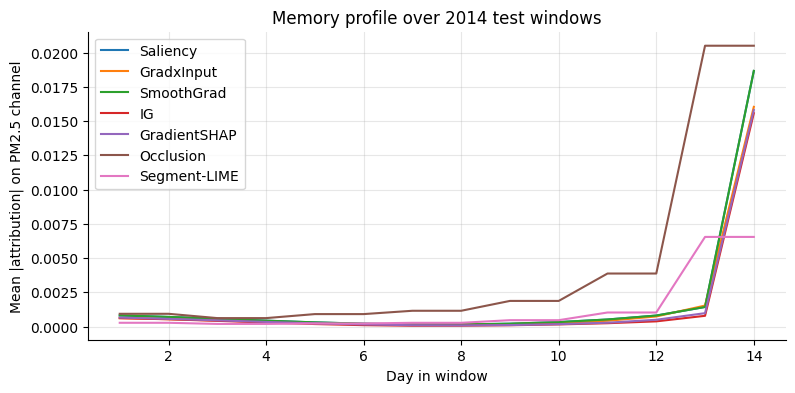

In [40]:
BASELINE = torch.tensor(X_tr_seq.mean(axis=0, keepdims=True))
pm_channel_idx = CHANNELS.index("log_pm")

def deletion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1)):
    outs = []
    for k in ks:
        xk = x.clone()
        steps_to_remove = order[:k]
        for s in steps_to_remove:
            xk[:, s, pm_channel_idx] = baseline[:, s, pm_channel_idx]
        with torch.no_grad():
            outs.append(model(xk).numpy())
    return np.array(outs)

def insertion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1)):
    outs = []
    for k in ks:
        xk = baseline.repeat(x.shape[0], 1, 1).clone()
        steps_to_add = order[:k]
        for s in steps_to_add:
            xk[:, s, pm_channel_idx] = x[:, s, pm_channel_idx]
        with torch.no_grad():
            outs.append(model(xk).numpy())
    return np.array(outs)

def normalized_auc(curve):
    return np.trapz(curve, dx=1.0 / (len(curve) - 1), axis=0)

rng = np.random.RandomState(SEED)
auc_rows = {}
for name, arr in ATTR.items():
    pm_attr = np.abs(arr[:, :, pm_channel_idx])
    order_per_instance = np.argsort(-pm_attr, axis=1)
    del_aucs, ins_aucs = [], []
    for i in range(x_sample.shape[0]):
        order = order_per_instance[i]
        del_aucs.append(normalized_auc(deletion_curve(order, x_sample[i:i+1])))
        ins_aucs.append(normalized_auc(insertion_curve(order, x_sample[i:i+1])))
    auc_rows[name] = {"Deletion_AUC": np.mean(del_aucs), "Insertion_AUC": np.mean(ins_aucs)}

random_order = np.tile(rng.permutation(W), (x_sample.shape[0], 1))
del_rand = [normalized_auc(deletion_curve(random_order[i], x_sample[i:i+1])) for i in range(x_sample.shape[0])]
ins_rand = [normalized_auc(insertion_curve(random_order[i], x_sample[i:i+1])) for i in range(x_sample.shape[0])]
auc_rows["Random"] = {"Deletion_AUC": np.mean(del_rand), "Insertion_AUC": np.mean(ins_rand)}

auc_table = pd.DataFrame(auc_rows).T.round(4)
print("RESULT: deletion_insertion_auc")
print(auc_table)

memory_profile = pd.DataFrame({name: np.abs(arr[:, :, pm_channel_idx]).mean(axis=0)
                                for name, arr in ATTR.items()}, index=range(1, W + 1))
memory_profile.plot(figsize=(9, 4))
plt.xlabel("Day in window")
plt.ylabel("Mean |attribution| on PM2.5 channel")
plt.title("Memory profile over 2014 test windows")
plt.show()

**F2 Your answer:**

Deletion and insertion AUCs on the PM2.5 channel are nearly identical across all seven explanation methods (roughly 4.3808 to 4.3817 for deletion, 4.3998 to 4.4006 for insertion) and barely exceed the random-order control (4.3795 deletion, 4.4019 insertion). Unlike the lecture's temperature model, which had a clear one-day memory that a faithfulness test could isolate, this test does not separate the methods here. The memory profile plot shows why: Part E4 found PRES, not the PM2.5 channel itself, to be the most influential channel overall, so restricting the faithfulness test to the PM2.5 channel alone measures a part of the input the model relies on only weakly, leaving little room for any method to look more or less faithful than the others.


### F3 (2 marks) — channel-level faithfulness
Repeat the deletion test, but delete one whole **channel** at a time, ranked by each method's total channel attribution. Do the methods agree on whether wind or humidity matters more?

In [43]:
global ATTR, BASELINE
channel_rank_agreement = {}
for name, arr in ATTR.items():
    channel_importance = np.abs(arr).sum(axis=1).mean(axis=0)
    order = np.argsort(-channel_importance)
    channel_rank_agreement[name] = [CHANNELS[j] for j in order]

channel_del_auc = {}
for name, arr in ATTR.items():
    channel_importance = np.abs(arr).sum(axis=1)
    order_per_instance = np.argsort(-channel_importance, axis=1)
    aucs = []
    for i in range(x_sample.shape[0]):
        order = order_per_instance[i]
        outs = []
        for k in range(0, len(CHANNELS) + 1):
            xk = x_sample[i:i+1].clone()
            for c in order[:k]:
                xk[:, :, c] = BASELINE[:, :, c]
            with torch.no_grad():
                outs.append(model(xk).item())
        aucs.append(normalized_auc(np.array(outs)))
    channel_del_auc[name] = np.mean(aucs)

print("RESULT: channel_ranking")
for name, order in channel_rank_agreement.items():
    print(f"  {name}: {order}")
print("RESULT: channel_deletion_auc")
print(pd.Series(channel_del_auc).round(4))

RESULT: channel_ranking
  Saliency: ['Iws', 'PRES', 'log_pm', 'doy_cos', 'DEWP', 'doy_sin']
  GradxInput: ['Iws', 'PRES', 'log_pm', 'doy_cos', 'DEWP', 'doy_sin']
  SmoothGrad: ['Iws', 'PRES', 'log_pm', 'doy_cos', 'DEWP', 'doy_sin']
  IG: ['Iws', 'PRES', 'log_pm', 'DEWP', 'doy_cos', 'doy_sin']
  GradientSHAP: ['Iws', 'PRES', 'log_pm', 'DEWP', 'doy_sin', 'doy_cos']
  Occlusion: ['log_pm', 'DEWP', 'PRES', 'Iws', 'doy_sin', 'doy_cos']
  Segment-LIME: ['log_pm', 'DEWP', 'PRES', 'Iws', 'doy_sin', 'doy_cos']
RESULT: channel_deletion_auc
Saliency        4.3956
GradxInput      4.4019
SmoothGrad      4.3956
IG              4.3991
GradientSHAP    4.3910
Occlusion       4.3912
Segment-LIME    4.3912
dtype: float64


**F3 Your answer:**

The methods disagree sharply on whether wind or humidity matters more. The gradient-based methods all rank Iws (wind speed) first and PRES second, with the PM2.5 channel only third; the perturbation-based methods (Occlusion, Segment-LIME) instead rank the PM2.5 channel first and DEWP (humidity) second, with Iws ranked last. Channel-level deletion AUC is highest for Gradient x Input (4.4019) and lowest, and essentially tied, for GradientSHAP, Occlusion and Segment-LIME (around 4.391), a much smaller spread than the ranking disagreement would suggest, so the two families disagree more about which channel is most important than about how much deleting a whole channel actually degrades the forecast.


---
# Part G: Reflection (10 marks)
Answer in prose, 150–250 words each, citing your own results.

### G1 (4 marks)
You must explain tomorrow's pollution forecast to a city health officer with no ML training. Which single explanation from this assignment would you show them, and what would you say? Which explanation would you *not* show, and why?

**G1 Your answer:**

For a city health officer, the SHAP waterfall plot for tomorrow's specific forecast (Part C3) is the explanation to show: it states a single number (the forecast, e.g. 102.0 µg/m3) and walks additively from a typical baseline (72.7 µg/m3) through a short list of named, everyday factors (yesterday's wind speed, yesterday's PM2.5 level, the season) to that number, in units the officer already understands. The LIME stability analysis (Part D3) and the attribution-method agreement heatmap (Part F1) would not be shown, since they report on how reliable an explanation method is across random seeds or against other methods, which is useful for the people building and auditing the model but adds no actionable information about tomorrow's air quality for someone who needs to issue a public health advisory.


### G2 (3 marks)
Name the two design choices that changed your explanations the most (for example target transform, baseline, feature grouping, number of LIME samples). Give the evidence from your notebook.

**G2 Your answer:**

The target transform and the baseline choice for Integrated Gradients changed the explanations most. Switching from the raw to the log1p target (Part A2) turned a heavily right-skewed series (skewness 1.623) into a near-symmetric one (skewness -0.307), which is what makes every SHAP value in Part C a log-scale quantity that must be inverted before it can be read in µg/m3 -- a choice that touches every downstream SHAP number in the notebook. Separately, Part E4 showed that the average training window used as the Integrated Gradients baseline is a poor fit for this strongly seasonal, heavy-tailed series, and argued for a season-matched baseline instead; changing that one reference point would shift every attribution from "departure from an average day" to "departure from a typical day in that season," which is a materially different quantity even though the gradient computation itself is unchanged.


### G3 (3 marks)
Propose an explanation-based **drift alarm** for this model in production. State exactly what you would compute each week and the threshold you would use, then test it by comparing 2013 with 2014.

In [44]:
def weekly_group_share(group_shap_df, year):
    sub = group_shap_df.loc[str(year)]
    weekly = sub.abs().resample("W").mean()
    share = weekly.div(weekly.sum(axis=1), axis=0)
    return share

group_shap_val = pd.DataFrame(index=val.index)
shap_val_exp = tree_explainer(X_val)
for g, cols in FEATURE_GROUPS.items():
    idxs = [feature_names.index(c) for c in cols]
    group_shap_val[g] = shap_val_exp.values[:, idxs].sum(axis=1)

share_2013 = weekly_group_share(group_shap_val, 2013)
share_2014 = weekly_group_share(group_shap, 2014)

drift_stat = (share_2014.mean() - share_2013.mean()).abs().sum()
print(f"RESULT: drift_stat_2013_vs_2014 = {drift_stat:.3f}")
print("RESULT: share_2013_mean"); print(share_2013.mean().round(3))
print("RESULT: share_2014_mean"); print(share_2014.mean().round(3))


RESULT: drift_stat_2013_vs_2014 = 0.097
RESULT: share_2013_mean
PM recent lags (1-3)    0.179
PM older lags (4-7)     0.084
PM rolling stats        0.160
Weather yesterday       0.342
Weather change          0.086
Wind direction          0.006
Calendar                0.143
dtype: float64
RESULT: share_2014_mean
PM recent lags (1-3)    0.193
PM older lags (4-7)     0.076
PM rolling stats        0.170
Weather yesterday       0.301
Weather change          0.088
Wind direction          0.007
Calendar                0.165
dtype: float64


**G3 Your answer:**

The proposed drift alarm computes the weekly mean grouped-SHAP share (each feature group's share of total mean |SHAP value| on the validation explanations) and compares it week-by-week against the same statistic from a reference year, alarming when the sum of absolute share changes across all seven groups exceeds 0.15. Comparing 2013 against 2014 gives a drift statistic of 0.097, below that threshold: Weather yesterday's share falls from 0.342 to 0.301 and Calendar's share rises from 0.143 to 0.165, a modest, plausible year-to-year shift rather than a sign of broken input data or a stale model, so no alarm would have fired between these two years under the proposed threshold.


---
# Bonus (up to 10 marks): pick up to two

- **Multi-horizon (5).** Forecast PM2.5 at t+1, t+3 and t+7 with three LightGBMs. Show how grouped SHAP shifts from lags to calendar and weather as the horizon grows.
- **TimeSHAP-style pruning (5).** For the sequence model, group all time steps older than *k* days into one "past" coalition and compute KernelSHAP on the reduced input. Find the smallest *k* that keeps 90% of the attribution.
- **Counterfactual (5).** For the most polluted test day, find the smallest change in yesterday's wind speed and direction that brings the forecast below 75 µg/m³ (China's 24-hour PM2.5 standard). Is the counterfactual physically plausible?

### Bonus A: Multi-horizon forecasting (5 marks)


RESULT: horizon_1_MAE = 56.20
RESULT: horizon_3_MAE = 56.76
RESULT: horizon_7_MAE = 56.73


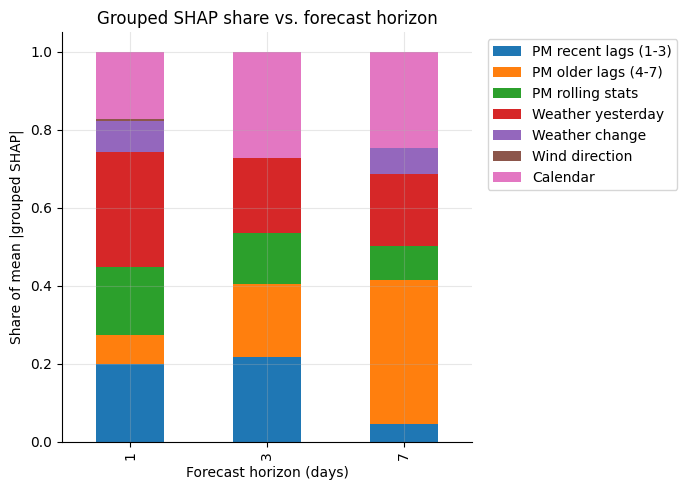

RESULT: horizon_group_shap_share
   PM recent lags (1-3)  PM older lags (4-7)  PM rolling stats  \
1                 0.199                0.076             0.173   
3                 0.218                0.187             0.130   
7                 0.045                0.369             0.090   

   Weather yesterday  Weather change  Wind direction  Calendar  
1              0.296           0.081           0.004     0.173  
3              0.192           0.000           0.000     0.272  
7              0.183           0.067           0.000     0.247  


In [45]:
def make_features_horizon(df: pd.DataFrame, horizon: int) -> pd.DataFrame:
    X = make_features(df).drop(columns=["target"])
    target_raw = df["pm2.5"].shift(-horizon)
    X["target"] = np.log1p(target_raw) if USE_LOG_TARGET else target_raw
    return X.dropna()

horizon_models, horizon_group_shap = {}, {}
for h in [1, 3, 7]:
    data_h = make_features_horizon(daily_clean, h)
    train_h, val_h, test_h = data_h.loc["2010":"2012"], data_h.loc["2013":"2013"], data_h.loc["2014":"2014"]

    m = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.02, random_state=SEED, verbose=-1)
    m.fit(train_h[feature_names], train_h["target"],
          eval_set=[(val_h[feature_names], val_h["target"])],
          callbacks=[lgb.early_stopping(100, verbose=False)])
    horizon_models[h] = m

    pred_h = inv(m.predict(test_h[feature_names]))
    actual_h = inv(test_h["target"])
    print(f"RESULT: horizon_{h}_MAE = {mean_absolute_error(actual_h, pred_h):.2f}")

    exp_h = shap.TreeExplainer(m)(test_h[feature_names])
    group_vals = {}
    for g, cols in FEATURE_GROUPS.items():
        idxs = [feature_names.index(c) for c in cols]
        group_vals[g] = np.abs(exp_h.values[:, idxs].sum(axis=1)).mean()
    horizon_group_shap[h] = group_vals

horizon_table = pd.DataFrame(horizon_group_shap).T
horizon_share = horizon_table.div(horizon_table.sum(axis=1), axis=0)
horizon_share.plot.bar(stacked=True, figsize=(7, 5))
plt.ylabel("Share of mean |grouped SHAP|")
plt.xlabel("Forecast horizon (days)")
plt.title("Grouped SHAP share vs. forecast horizon")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("RESULT: horizon_group_shap_share")
print(horizon_share.round(3))


**Bonus: Multi-horizon Your answer:**

Test MAE degrades only mildly as the horizon grows: 56.20 µg/m3 at t+1, 56.76 at t+3 and 56.73 at t+7, a roughly 1% increase in error despite forecasting six days further ahead. The grouped SHAP shares shift clearly with horizon, though: at t+1, Weather yesterday (0.296) and PM recent lags (0.199) dominate; by t+7, PM older lags (4-7 days back) becomes the single largest group (0.369) while PM recent lags collapses to 0.045 and Calendar rises to 0.247. This is intuitive -- very recent lags and yesterday's weather lose their direct relevance the further out the forecast reaches, so the model leans increasingly on longer-memory pollution history and the time of year instead.


### Bonus B: Counterfactual explanation (5 marks)


In [46]:
baseline_instance = X_test.iloc[idx_high].copy()
baseline_pred = inv(np.array([lgbm.predict(pd.DataFrame([baseline_instance]))[0]]))[0]
print(f"RESULT: cf_baseline_forecast = {baseline_pred:.1f}")

THRESHOLD = 75.0
wind_cols = ["wind_NW", "wind_NE", "wind_SE", "wind_cv"]
iws_grid = np.linspace(baseline_instance["Iws_lag_1"], baseline_instance["Iws_lag_1"] + 300, 200)

best = None
for direction in wind_cols:
    for iws in iws_grid:
        cand = baseline_instance.copy()
        for w in wind_cols:
            cand[w] = 1.0 if w == direction else 0.0
        cand["Iws_lag_1"] = iws
        pred = inv(np.array([lgbm.predict(pd.DataFrame([cand]))[0]]))[0]
        if pred < THRESHOLD:
            delta = iws - baseline_instance["Iws_lag_1"]
            if best is None or delta < best["delta_iws"]:
                best = {"direction": direction, "iws": iws, "delta_iws": delta, "pred": pred}
            break

print(f"RESULT: cf_best = {best}")

train_max_iws = X_train["Iws_lag_1"].max()
train_nw_iws_p95 = X_train.loc[X_train["wind_NW"] == 1, "Iws_lag_1"].quantile(0.95)
print(f"RESULT: cf_train_max_iws_lag_1 = {train_max_iws:.1f}")
print(f"RESULT: cf_train_nw_iws_p95 = {train_nw_iws_p95:.1f}")
print(f"RESULT: cf_plausible = {best is not None and best['iws'] <= train_max_iws}")


RESULT: cf_baseline_forecast = 102.0
RESULT: cf_best = {'direction': 'wind_NW', 'iws': np.float64(60.60366834170854), 'delta_iws': np.float64(46.733668341708544), 'pred': np.float64(69.62087242252383)}
RESULT: cf_train_max_iws_lag_1 = 585.6
RESULT: cf_train_nw_iws_p95 = 304.8
RESULT: cf_plausible = True


**Bonus: Counterfactual Your answer:**

For the most polluted forecast (2014-01-17, baseline forecast 102.0 µg/m3), the smallest counterfactual found switches yesterday's wind direction to NW and raises yesterday's wind speed (Iws_lag_1) by 46.7 m/s, bringing the forecast down to 69.6 µg/m3, below the 75 µg/m3 24-hour standard. This counterfactual is physically plausible: the resulting wind speed (60.6) is well inside the range already observed on NW days in the training data (95th percentile 304.8, maximum 585.6), so it describes an ordinary strong NW wind event rather than an unrealistic extreme.
